In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import pickle
import random
import time
import seaborn as sns
import numpy as np
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from matplotlib.ticker import FormatStrFormatter
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, f1_score, classification_report, roc_auc_score, make_scorer, precision_recall_fscore_support
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint
from sklearn.utils import resample
from imblearn.over_sampling import SMOTE

## Объединение датасетов и очистка данных

In [3]:
df_sessions = pd.read_csv('data/ga_sessions.csv')
df_sessions

/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_29445/1710953944.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sessions = pd.read_csv('data/ga_sessions.csv')


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22,10:48:25,1,BHcvLfOaCWvWTykYqHVe,cpc,NaN,NaN,VlqBmecIOXWjCWUmQkLd,desktop,Windows,NaN,NaN,1920x1080,Chrome,Russia,Moscow
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,390x844,Safari,Russia,Stavropol
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15,15:31:55,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,NaN,375x667,Safari,Russia,Moscow
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29,15:36:44,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x851,Chrome,Russia,Chelyabinsk


In [4]:
df_hits = pd.read_csv('data/ga_hits.csv')
df_hits

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
15726465,6866159858916559617.1640270865.1640270865,2021-12-23,810589.0,43,event,NaN,sberauto.com/cars/all/toyota/fortuner/24cb5af2...,quiz,quiz_show,NaN,NaN
15726466,7310304587364460692.1640261783.1640261783,2021-12-23,904927.0,40,event,NaN,sberauto.com/cars/all/mercedes-benz/gla-klasse...,quiz,quiz_show,NaN,NaN
15726467,8013702685784312179.1640270195.1640270195,2021-12-23,2172865.0,43,event,NaN,sberauto.com/cars/all/toyota/alphard/2ebe4871?...,quiz,quiz_show,NaN,NaN
15726468,8021505554734405918.1640257821.1640257821,2021-12-23,713325.0,45,event,NaN,sberauto.com/cars/all/bmw/x3/6a660f0a?rental_p...,quiz,quiz_show,NaN,NaN


In [5]:
df_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
dtypes: int64(1), object(17)
memory usage: 255.4+ MB


In [6]:
df_hits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   session_id      object 
 1   hit_date        object 
 2   hit_time        float64
 3   hit_number      int64  
 4   hit_type        object 
 5   hit_referer     object 
 6   hit_page_path   object 
 7   event_category  object 
 8   event_action    object 
 9   event_label     object 
 10  event_value     float64
dtypes: float64(2), int64(1), object(8)
memory usage: 1.3+ GB


In [7]:
df_hits.nunique(dropna=False)

session_id        1734610
hit_date              226
hit_time           925888
hit_number            500
hit_type                1
hit_referer         37874
hit_page_path      342715
event_category         52
event_action          230
event_label         39826
event_value             1
dtype: int64

In [8]:
df_sessions.nunique(dropna=False)

session_id                  1860042
client_id                   1391717
visit_date                      226
visit_time                    85318
visit_number                    537
utm_source                      294
utm_medium                       56
utm_campaign                    413
utm_adcontent                   287
utm_keyword                    1220
device_category                   3
device_os                        14
device_brand                    206
device_model                    105
device_screen_resolution       5039
device_browser                   57
geo_country                     166
geo_city                       2548
dtype: int64

In [9]:
# Список целевых действий
target_actions = [
    'sub_car_claim_click', 'sub_car_claim_submit_click',
    'sub_open_dialog_click', 'sub_custom_question_submit_click',
    'sub_call_number_click', 'sub_callback_submit_click',
    'sub_submit_success', 'sub_car_request_submit_click'
]

# Создаем столбец is_target
df_hits['target'] = df_hits['event_action'].isin(target_actions).astype(int)

# Подсчет количества целевых и нецелевых
target_counts = df_hits['target'].value_counts()
print("Количество строк с целевыми и нецелевыми event_action:")
print(f"Целевые (target=1): {target_counts.get(1, 0)}")
print(f"Нецелевые (target=0): {target_counts.get(0, 0)}")

# Подсчет пропорций
target_proportions = df_hits['target'].value_counts(normalize=True)
print("\nПропорции целевых и нецелевых event_action:")
print(f"Целевые (target=1): {target_proportions.get(1, 0):.4f}")
print(f"Нецелевые (target=0): {target_proportions.get(0, 0):.4f}")

# Подсчет каждого целевого действия
print("\nКоличество строк для каждого целевого event_action:")
target_action_counts = df_hits[df_hits['event_action'].isin(target_actions)]['event_action'].value_counts()
print(target_action_counts)

Количество строк с целевыми и нецелевыми event_action:
Целевые (target=1): 104908
Нецелевые (target=0): 15621562

Пропорции целевых и нецелевых event_action:
Целевые (target=1): 0.0067
Нецелевые (target=0): 0.9933

Количество строк для каждого целевого event_action:
event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
Name: count, dtype: int64


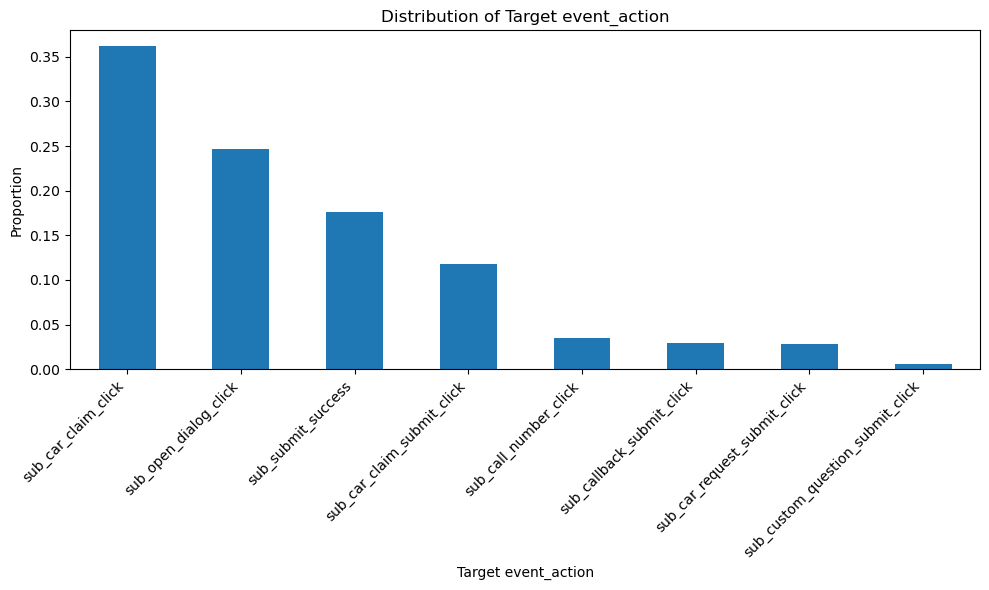

In [10]:
# Фильтруем df_hits только по целевым event_action
target_hits = df_hits[df_hits['event_action'].isin(target_actions)]

# Строим бар-график с пропорциями
target_hits['event_action'].value_counts(normalize=True).plot(
    kind='bar', 
    figsize=(10, 6), 
    title="Distribution of Target event_action"
)

plt.xlabel("Target event_action")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha='right')  
plt.tight_layout()  
plt.show()

In [11]:
df_combined = pd.merge(df_sessions, df_hits, on='session_id', how='left')
df_combined

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value,target
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,3665.0,3.0,event,NaN,podpiska.sberauto.com/,sub_page_view,sub_landing,NaN,NaN,0.0
1,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,46592.0,4.0,event,NaN,podpiska.sberauto.com/,sub_button_click,sub_view_cars_click,vodKSlUobUWTVlgsJqdI,NaN,0.0
2,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,921.0,3.0,event,NaN,podpiska.sberauto.com/,sub_page_view,sub_landing,NaN,NaN,0.0
3,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,84155.0,10.0,event,NaN,sberauto.com/cars?utm_source_initial=sbol&utm_...,search_form,search_form_region,KWTCzSIXzoqUWjfUQMgP,NaN,0.0
4,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,102979.0,13.0,event,NaN,sberauto.com/cars?utm_source_initial=sbol&utm_...,search_form,search_form_region,CBqnBQaKoQUyWJhLcxxN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15812990,9055430416266113553.1640968742.1640968742,2108381692.164097,2021-12-31,19:39:02,1,fgymSoTvjKPEgaIJqsiH,cpm,FTjNLDyTrXaWYgZymFkV,yYdBRbPmBMUZHXwqGxNx,oKjXDUsycmahkgMhGdAR,...,33010.0,11.0,event,NaN,sberauto.com/cars/all/bmw/3-serii/bde2c9d5?utm...,card_web,view_card,NaN,NaN,0.0
15812991,9055430416266113553.1640968742.1640968742,2108381692.164097,2021-12-31,19:39:02,1,fgymSoTvjKPEgaIJqsiH,cpm,FTjNLDyTrXaWYgZymFkV,yYdBRbPmBMUZHXwqGxNx,oKjXDUsycmahkgMhGdAR,...,34694.0,16.0,event,NaN,sberauto.com/cars/all/bmw/3-serii/bde2c9d5?utm...,card_web,view_new_card,NaN,NaN,0.0
15812992,9055430416266113553.1640968742.1640968742,2108381692.164097,2021-12-31,19:39:02,1,fgymSoTvjKPEgaIJqsiH,cpm,FTjNLDyTrXaWYgZymFkV,yYdBRbPmBMUZHXwqGxNx,oKjXDUsycmahkgMhGdAR,...,250.0,3.0,event,NaN,sberauto.com/cars/all/mercedes-benz/e-klasse/d...,card_web,view_card,NaN,NaN,0.0
15812993,9055430416266113553.1640968742.1640968742,2108381692.164097,2021-12-31,19:39:02,1,fgymSoTvjKPEgaIJqsiH,cpm,FTjNLDyTrXaWYgZymFkV,yYdBRbPmBMUZHXwqGxNx,oKjXDUsycmahkgMhGdAR,...,33533.0,14.0,event,NaN,sberauto.com/cars/all/bmw/3-serii/bde2c9d5?utm...,card_web,view_card,NaN,NaN,0.0


In [12]:
agg_hits = df_combined.groupby('session_id').agg(
    target=('target', 'max'),  # Была ли хоть одна целевая активность
    n_hits=('hit_type', 'count'),
    n_pages=('hit_page_path', 'nunique'),
    n_events=('event_action', 'count'),
    n_event_types=('event_action', 'nunique'),
    n_hit_types=('hit_type', 'nunique'),
    session_duration=('hit_time', lambda x: x.max() - x.min())
).reset_index()
agg_hits

,session_id,target,n_hits,n_pages,n_events,n_event_types,n_hit_types,session_duration
0,1000009318903347362.1632663668.1632663668,0.0,10,3,10,6,1,NaN
1,1000010177899156286.1635013443.1635013443,0.0,6,2,6,5,1,238700.0
2,1000013386240115915.1635402956.1635402956,0.0,11,3,11,6,1,170554.0
3,1000017303238376207.1623489300.1623489300,0.0,12,3,12,8,1,NaN
4,1000020580299877109.1624943350.1624943350,0.0,1,1,1,1,1,NaN
...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0.0,2,1,2,2,1,NaN
1860038,999966717128502952.1638428330.1638428330,0.0,12,2,12,6,1,113657.0
1860039,999969216784562223.1623521327.1623521327,NaN,0,0,0,0,0,NaN
1860040,999988617151873171.1623556243.1623556243,0.0,4,2,4,4,1,NaN


In [13]:
df_combined = agg_hits.merge(df_sessions, on='session_id', how='left')
df_combined

,session_id,target,n_hits,n_pages,n_events,n_event_types,n_hit_types,session_duration,client_id,visit_date,...,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,1000009318903347362.1632663668.1632663668,0.0,10,3,10,6,1,NaN,232832813.163266,2021-09-26,...,PkybGvWbaqORmxjNunqZ,NaN,mobile,NaN,Samsung,NaN,412x869,Chrome,Russia,Gelendzhik
1,1000010177899156286.1635013443.1635013443,0.0,6,2,6,5,1,238700.0,232833013.163501,2021-10-23,...,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,NaN,360x640,Samsung Internet,Russia,Voronezh
2,1000013386240115915.1635402956.1635402956,0.0,11,3,11,6,1,170554.0,232833760.16354,2021-10-28,...,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,NaN,412x846,Chrome,Russia,Cherkessk
3,1000017303238376207.1623489300.1623489300,0.0,12,3,12,8,1,NaN,232834672.162349,2021-06-12,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Realme,NaN,360x780,Chrome,Russia,Irkutsk
4,1000020580299877109.1624943350.1624943350,0.0,1,1,1,1,1,NaN,232835435.162494,2021-06-29,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,414x736,Safari,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0.0,2,1,2,2,1,NaN,23282272.162681,2021-07-20,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,375x667,Safari,Russia,Saint Petersburg
1860038,999966717128502952.1638428330.1638428330,0.0,12,2,12,6,1,113657.0,232822894.163843,2021-12-02,...,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x873,Chrome,Russia,Nizhny Novgorod
1860039,999969216784562223.1623521327.1623521327,NaN,0,0,0,0,0,NaN,232823476.162352,2021-06-12,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,375x812,Safari,Russia,Moscow
1860040,999988617151873171.1623556243.1623556243,0.0,4,2,4,4,1,NaN,232827993.162356,2021-06-13,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Samsung,NaN,412x732,Samsung Internet,Russia,Chelyabinsk


In [14]:
df_combined['target'] = df_combined['target'].fillna(0).astype(int)

In [15]:
df_combined['target'].value_counts(dropna=False)

target
0    1809728
1      50314
Name: count, dtype: int64

In [16]:
client_session_counts = df_sessions['client_id'].value_counts()
client_session_counts

client_id
1.750498e+09    462
1.309184e+08    334
1.266575e+09    309
7.368596e+08    306
1.894772e+09    276
               ... 
8.789419e+08      1
8.789399e+08      1
8.789397e+08      1
8.789339e+08      1
2.108382e+09      1
Name: count, Length: 1391717, dtype: int64

In [17]:
bots = client_session_counts[client_session_counts > 100].index  # порог можно подобрать
bots

Index([      1750498477.162945,       130918396.1628014,
             1266574870.162314,       736859557.1619557,
             1894772482.162186,       1065181919.163161,
             1136708344.163342,      1761941933.1621838,
            260799907.16309997,       943676978.1621888,
        '471358394.1635690930',       75736298.16231383,
             608193703.1627332,       1705502122.162704,
             3326811.163178227,       1349127172.163766,
            1780145432.1626253,      1364722753.1617804,
            319254641.16221315,      130888842.16260836,
            1696107223.1607704,      484088880.16151166,
            1216284533.1631196,      114662046.16352735,
            1491419962.1625211, '1428181464.1617515791',
            1793270478.1636696,       1480519789.162928,
             1290942816.162717,       1617539083.160931,
            1750034133.1617036,      1985320892.1617255,
             699717563.1622044,      1004110209.1631685,
            1485840051.1622207,

In [18]:
df_combined = df_combined[~df_combined['client_id'].isin(bots)]
df_combined

,session_id,target,n_hits,n_pages,n_events,n_event_types,n_hit_types,session_duration,client_id,visit_date,...,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,1000009318903347362.1632663668.1632663668,0,10,3,10,6,1,NaN,232832813.163266,2021-09-26,...,PkybGvWbaqORmxjNunqZ,NaN,mobile,NaN,Samsung,NaN,412x869,Chrome,Russia,Gelendzhik
1,1000010177899156286.1635013443.1635013443,0,6,2,6,5,1,238700.0,232833013.163501,2021-10-23,...,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,NaN,360x640,Samsung Internet,Russia,Voronezh
2,1000013386240115915.1635402956.1635402956,0,11,3,11,6,1,170554.0,232833760.16354,2021-10-28,...,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,NaN,412x846,Chrome,Russia,Cherkessk
3,1000017303238376207.1623489300.1623489300,0,12,3,12,8,1,NaN,232834672.162349,2021-06-12,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Realme,NaN,360x780,Chrome,Russia,Irkutsk
4,1000020580299877109.1624943350.1624943350,0,1,1,1,1,1,NaN,232835435.162494,2021-06-29,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,414x736,Safari,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0,2,1,2,2,1,NaN,23282272.162681,2021-07-20,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,375x667,Safari,Russia,Saint Petersburg
1860038,999966717128502952.1638428330.1638428330,0,12,2,12,6,1,113657.0,232822894.163843,2021-12-02,...,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x873,Chrome,Russia,Nizhny Novgorod
1860039,999969216784562223.1623521327.1623521327,0,0,0,0,0,0,NaN,232823476.162352,2021-06-12,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,375x812,Safari,Russia,Moscow
1860040,999988617151873171.1623556243.1623556243,0,4,2,4,4,1,NaN,232827993.162356,2021-06-13,...,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Samsung,NaN,412x732,Samsung Internet,Russia,Chelyabinsk


In [19]:
df_combined['target'].value_counts(dropna=False)

target
0    1798835
1      49780
Name: count, dtype: int64

In [20]:
df_combined = df_combined.drop(columns=['n_hit_types','n_event_types','n_events', 'n_pages', 'n_hits', 'session_duration'])

In [21]:
df_combined.nunique(dropna=False)

session_id                  1848615
target                            2
client_id                   1391649
visit_date                      226
visit_time                    85316
visit_number                    255
utm_source                      292
utm_medium                       56
utm_campaign                    404
utm_adcontent                   285
utm_keyword                    1220
device_category                   3
device_os                        14
device_brand                    206
device_model                    105
device_screen_resolution       5038
device_browser                   57
geo_country                     166
geo_city                       2548
dtype: int64

In [22]:
def print_useful_rows_info(df):
    filled_rows = df.dropna()
    print('Количество заполненных строк:', len(filled_rows))
    print('Процент заполненных строк:', round(len(filled_rows) / len(df) * 100, 2))
    print('Количество строк с NaN:', df.isna().sum().sum())
    print('Процент строк с NaN:', round(df.isna().sum().sum() / df.size * 100, 2))

print_useful_rows_info(df_combined)

Количество заполненных строк: 14894
Процент заполненных строк: 0.81
Количество строк с NaN: 4879009
Процент строк с NaN: 13.89


In [23]:
df_combined.isna().sum().sort_values(ascending=False)

device_model                1832385
utm_keyword                 1075014
device_os                   1063093
device_brand                 357547
utm_adcontent                333159
utm_campaign                 217714
utm_source                       97
device_category                   0
geo_country                       0
device_browser                    0
device_screen_resolution          0
session_id                        0
target                            0
utm_medium                        0
visit_number                      0
visit_time                        0
visit_date                        0
client_id                         0
geo_city                          0
dtype: int64

In [24]:
df_combined['target'].value_counts(dropna=False)

target
0    1798835
1      49780
Name: count, dtype: int64

In [25]:
df_combined['device_model'].value_counts(dropna=False)

device_model
NaN                     1832385
AuMdmADEIoPXiWpTsBEj       9670
tWBQlsvNfHxRUjaPAfhd        653
cwMJxNXiWUgMUxGiCTPs        651
pTgAEPipQxDXCjPrJbHo        461
                         ...   
qmRODeCJLlmkmwxNYXvp          1
MBGYWAQSYWUphNxTsAWD          1
VDidzTqFGxuqiRQJGrwB          1
OJiWyBKOyDITzXCZRSMH          1
JNHcPlZPxEMWDnRiyoBf          1
Name: count, Length: 105, dtype: int64

In [26]:
df_combined.device_model=df_combined.device_model.fillna('other')
df_combined['device_model'].value_counts(dropna=False)

device_model
other                   1832385
AuMdmADEIoPXiWpTsBEj       9670
tWBQlsvNfHxRUjaPAfhd        653
cwMJxNXiWUgMUxGiCTPs        651
pTgAEPipQxDXCjPrJbHo        461
                         ...   
qmRODeCJLlmkmwxNYXvp          1
MBGYWAQSYWUphNxTsAWD          1
VDidzTqFGxuqiRQJGrwB          1
OJiWyBKOyDITzXCZRSMH          1
JNHcPlZPxEMWDnRiyoBf          1
Name: count, Length: 105, dtype: int64

In [27]:
df_combined['device_os'].value_counts(dropna=False)

device_os
NaN              1063093
Android           463358
iOS               207081
Windows            84998
Macintosh          24482
Linux               5108
(not set)            364
Chrome OS             83
BlackBerry            27
Tizen                  7
Samsung                4
Windows Phone          4
Firefox OS             3
Nokia                  3
Name: count, dtype: int64

In [28]:
df_combined.device_os=df_combined.device_os.fillna('other')
df_combined['device_os'].value_counts(dropna=False)

device_os
other            1063093
Android           463358
iOS               207081
Windows            84998
Macintosh          24482
Linux               5108
(not set)            364
Chrome OS             83
BlackBerry            27
Tizen                  7
Samsung                4
Windows Phone          4
Firefox OS             3
Nokia                  3
Name: count, dtype: int64

In [29]:
df_combined['device_brand'].value_counts(dropna=False)

device_brand
Apple       550824
NaN         357547
Samsung     331440
Xiaomi      288367
Huawei      185499
             ...  
Tesla            1
Vodafone         1
Wexler           1
Smarteo          1
Opera            1
Name: count, Length: 206, dtype: int64

In [30]:
df_combined.device_brand=df_combined.device_brand.fillna('other')
df_combined['device_brand'].value_counts(dropna=False)

device_brand
Apple       550824
other       357547
Samsung     331440
Xiaomi      288367
Huawei      185499
             ...  
Tesla            1
Vodafone         1
Wexler           1
Smarteo          1
Opera            1
Name: count, Length: 206, dtype: int64

In [31]:
df_combined['utm_keyword'].value_counts(dropna=False)

utm_keyword
NaN                     1075014
puhZPIYqKXeFPaUviSjo     504490
aXQzDWsJuGXeBXexNHjc      24230
pHqgLcdBQPSLcrTpLkdr      13767
ITfrGJNwVsHBGJMAKoct      12741
                         ...   
MQKcTjzuZISZCrJZNuBo          1
uucOIlRysdLPcqDPWItw          1
MBGYWAQSYWUphNxTsAWD          1
lGmMXrMkjZsdbfpkENcb          1
DlOlXJaBJgWQVhgtCeWo          1
Name: count, Length: 1220, dtype: int64

In [32]:
df_combined['utm_adcontent'].value_counts(dropna=False)

utm_adcontent
JNHcPlZPxEMWDnRiyoBf    998567
NaN                     333159
vCIpmpaGBnIQhyYNkXqp    181045
xhoenQgDQsgfEPYNPwKO    113072
PkybGvWbaqORmxjNunqZ     60315
                         ...  
PlanrlymnpCeYvUrUTVJ         1
WbXQsVOKLOcJrHikuQTZ         1
uBUwgolUDgFUqOyprsyw         1
JqrDmBADqCajaFvukKzI         1
zQEFTgQvqExfbldEpotc         1
Name: count, Length: 285, dtype: int64

In [33]:
df_combined['utm_campaign'].value_counts(dropna=False)

utm_campaign
LTuZkdKfxRGVceoWkVyg    456663
LEoPHuyFvzoNfnzGgfcd    324039
FTjNLDyTrXaWYgZymFkV    247358
NaN                     217714
gecBYcKZCPMcVYdSSzKP    133993
                         ...  
zXjuoqEaPElBnwpSHMpx         1
cqgnjDbqrtCipVvzhxqa         1
AdtHYglxfCpTpwZeTAuW         1
pcvPxfVFaAmhwFmvIeYd         1
RkpOyeEPgcMBSDuHLQcj         1
Name: count, Length: 404, dtype: int64

In [34]:
df_combined['utm_source'].value_counts(dropna=False)

utm_source
ZpYIoDJMcFzVoPFsHGJL    578193
fDLlAcSmythWSCVMvqvL    297784
kjsLglQLzykiRbcDiGcD    262955
MvfHsxITijuriZxsqZqt    186185
BHcvLfOaCWvWTykYqHVe    115719
                         ...  
ZsHOHNXkbhgIDlKNiFMf         1
hYVrCkhCPSqKBhZYhWVq         1
OboZzsWwJIeGPLeiLGMq         1
kKtSojgDlfomwthXhPjz         1
jqlUOdZBNZYfInQVcZlS         1
Name: count, Length: 292, dtype: int64

In [35]:
# Список столбцов для заполнения
utm_columns = ['utm_keyword', 'utm_adcontent', 'utm_campaign', 'utm_source']

# Проверка пропусков до заполнения
print("Количество пропусков до заполнения:")
print(df_combined[utm_columns].isna().sum())

# Вывод моды для каждого столбца
print("\nНаиболее популярные значения (мода) для каждого столбца:")
for col in utm_columns:
    mode_value = df_combined[col].mode()[0]
    print(f"{col}: {mode_value}")

# Заполнение NaN модой
for col in utm_columns:
    mode_value = df_combined[col].mode()[0]
    df_combined[col] = df_combined[col].fillna(mode_value)

# Проверка пропусков после заполнения
print("\nКоличество пропусков после заполнения:")
print(df_combined[utm_columns].isna().sum())

# Проверка распределения значений после заполнения
for col in utm_columns:
    print(f"\nРаспределение значений в {col} после заполнения:")
    print(df_combined[col].value_counts().head(5))

Количество пропусков до заполнения:
utm_keyword      1075014
utm_adcontent     333159
utm_campaign      217714
utm_source            97
dtype: int64

Наиболее популярные значения (мода) для каждого столбца:
utm_keyword: puhZPIYqKXeFPaUviSjo
utm_adcontent: JNHcPlZPxEMWDnRiyoBf
utm_campaign: LTuZkdKfxRGVceoWkVyg
utm_source: ZpYIoDJMcFzVoPFsHGJL

Количество пропусков после заполнения:
utm_keyword      0
utm_adcontent    0
utm_campaign     0
utm_source       0
dtype: int64

Распределение значений в utm_keyword после заполнения:
utm_keyword
puhZPIYqKXeFPaUviSjo    1579504
aXQzDWsJuGXeBXexNHjc      24230
pHqgLcdBQPSLcrTpLkdr      13767
ITfrGJNwVsHBGJMAKoct      12741
hAmNSZmQkKQKAjZEGlgb      10983
Name: count, dtype: int64

Распределение значений в utm_adcontent после заполнения:
utm_adcontent
JNHcPlZPxEMWDnRiyoBf    1331726
vCIpmpaGBnIQhyYNkXqp     181045
xhoenQgDQsgfEPYNPwKO     113072
PkybGvWbaqORmxjNunqZ      60315
LLfCasrxQzJIyuldcuWy      24211
Name: count, dtype: int64

Распределение

In [36]:
df_combined.isna().sum()

session_id                  0
target                      0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
utm_keyword                 0
device_category             0
device_os                   0
device_brand                0
device_model                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
dtype: int64

In [37]:
df_combined = df_combined.dropna(subset=['client_id'])
df_combined.isna().sum()

session_id                  0
target                      0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
utm_keyword                 0
device_category             0
device_os                   0
device_brand                0
device_model                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
dtype: int64

In [38]:
df_combined

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,1000009318903347362.1632663668.1632663668,0,232832813.163266,2021-09-26,16:00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Chrome,Russia,Gelendzhik
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23,21:24:03,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh
2,1000013386240115915.1635402956.1635402956,0,232833760.16354,2021-10-28,09:35:56,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,412x846,Chrome,Russia,Cherkessk
3,1000017303238376207.1623489300.1623489300,0,232834672.162349,2021-06-12,12:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Realme,other,360x780,Chrome,Russia,Irkutsk
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0,23282272.162681,2021-07-20,23:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x667,Safari,Russia,Saint Petersburg
1860038,999966717128502952.1638428330.1638428330,0,232822894.163843,2021-12-02,09:58:50,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x873,Chrome,Russia,Nizhny Novgorod
1860039,999969216784562223.1623521327.1623521327,0,232823476.162352,2021-06-12,21:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,Safari,Russia,Moscow
1860040,999988617151873171.1623556243.1623556243,0,232827993.162356,2021-06-13,06:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x732,Samsung Internet,Russia,Chelyabinsk


In [39]:
df_combined['visit_number'].value_counts(dropna=False)

visit_number
1      1376286
2       235598
3        81011
4        41607
5        24208
        ...   
254          1
244          1
242          1
240          1
139          1
Name: count, Length: 255, dtype: int64

In [40]:
# Проверить, есть ли дубликаты
duplicates = df_combined.duplicated()

print(f"Количество дубликатов: {duplicates.sum()}")
print(df_combined[duplicates])

Количество дубликатов: 0
Empty DataFrame
Columns: [session_id, target, client_id, visit_date, visit_time, visit_number, utm_source, utm_medium, utm_campaign, utm_adcontent, utm_keyword, device_category, device_os, device_brand, device_model, device_screen_resolution, device_browser, geo_country, geo_city]
Index: []


In [41]:
df_combined

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,1000009318903347362.1632663668.1632663668,0,232832813.163266,2021-09-26,16:00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Chrome,Russia,Gelendzhik
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23,21:24:03,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh
2,1000013386240115915.1635402956.1635402956,0,232833760.16354,2021-10-28,09:35:56,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,412x846,Chrome,Russia,Cherkessk
3,1000017303238376207.1623489300.1623489300,0,232834672.162349,2021-06-12,12:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Realme,other,360x780,Chrome,Russia,Irkutsk
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0,23282272.162681,2021-07-20,23:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x667,Safari,Russia,Saint Petersburg
1860038,999966717128502952.1638428330.1638428330,0,232822894.163843,2021-12-02,09:58:50,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x873,Chrome,Russia,Nizhny Novgorod
1860039,999969216784562223.1623521327.1623521327,0,232823476.162352,2021-06-12,21:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,Safari,Russia,Moscow
1860040,999988617151873171.1623556243.1623556243,0,232827993.162356,2021-06-13,06:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x732,Samsung Internet,Russia,Chelyabinsk


In [42]:
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1848615 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   target                    int64 
 2   client_id                 object
 3   visit_date                object
 4   visit_time                object
 5   visit_number              int64 
 6   utm_source                object
 7   utm_medium                object
 8   utm_campaign              object
 9   utm_adcontent             object
 10  utm_keyword               object
 11  device_category           object
 12  device_os                 object
 13  device_brand              object
 14  device_model              object
 15  device_screen_resolution  object
 16  device_browser            object
 17  geo_country               object
 18  geo_city                  object
dtypes: int64(2), object(17)
memory usage: 282.1+ MB


In [43]:
none_rows = df_combined[df_combined['utm_medium'] == '(none)']
none_rows

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23,21:24:03,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
5,1000020580299877109.1624972957.1624972957,0,232835435.162494,2021-06-29,16:00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
6,1000020580299877109.1624980453.1624980453,0,232835435.162494,2021-06-29,18:00:00,3,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
12,1000043953525145011.1638186424.1638186424,0,232840877.163819,2021-11-29,14:47:04,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x851,YaBrowser,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860013,999819477043134339.1621901188.1621901188,1,232788612.16219,2021-05-25,03:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x896,Chrome,Russia,Saint Petersburg
1860020,999869912844216646.1622026578.1622026578,0,232800355.162203,2021-05-26,13:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x915,Chrome,Russia,Moscow
1860021,999869912844216646.1622030933.1622030933,1,232800355.162203,2021-05-26,15:00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x915,Chrome,Russia,Moscow
1860035,999957431392736135.1621955463.1621955463,0,232820732.162196,2021-05-25,18:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,390x844,Safari,Russia,Moscow


In [44]:
not_set_rows = df_combined[df_combined['device_os'] == '(not set)']
not_set_rows

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
7644,1035604873987172629.1638607124.1638607124,0,241120549.163861,2021-12-04,11:38:44,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,Moscow
9863,104498608946512525.1640465036.1640465036,0,24330478.164047,2021-12-25,23:43:56,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,(not set)
10502,1048005170422293907.1640703380.1640703380,0,244007718.16407,2021-12-28,17:56:20,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,Saint Petersburg
16778,1076239989071120250.1638369148.1638369148,0,250581649.163837,2021-12-01,17:32:28,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,Saint Petersburg
22277,1101499542140844398.1636792689.1636792689,0,256462847.163679,2021-11-13,11:38:09,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,Instagram 213.0.0.29.120 Android,United States,Fort Worth
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1835520,9192716748074205719.1639924247.1639924247,0,2140346157.163992,2021-12-19,17:30:47,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,(not set)
1842763,924373643453455998.1640423038.1640423038,0,215222510.164042,2021-12-25,12:03:58,1,QxAxdyPLuQMEcrdZWdWb,cpa,mSVMBvlHFgftJaQAZEdp,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,Instagram 216.1.0.21.137 Android,Ireland,Dublin
1843137,926277735599476462.1640140530.1640140530,0,215665841.164014,2021-12-22,05:35:30,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,Nizhny Tagil
1852464,966942485956400150.1638536213.1638536213,0,225133841.163854,2021-12-03,15:56:53,1,QxAxdyPLuQMEcrdZWdWb,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,(not set),(not set),AuMdmADEIoPXiWpTsBEj,2000x2000,Opera Mini,United States,Prineville


## Типы данных и визуализация, удаление выбросов

In [46]:
df_combined['visit_date'] = pd.to_datetime(df_combined['visit_date'],format='%Y-%m-%d', utc=True)
df_combined['visit_time'] = pd.to_datetime(df_combined['visit_time'],format='%H:%M:%S', utc=True)
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1848615 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   target                    int64              
 2   client_id                 object             
 3   visit_date                datetime64[ns, UTC]
 4   visit_time                datetime64[ns, UTC]
 5   visit_number              int64              
 6   utm_source                object             
 7   utm_medium                object             
 8   utm_campaign              object             
 9   utm_adcontent             object             
 10  utm_keyword               object             
 11  device_category           object             
 12  device_os                 object             
 13  device_brand              object             
 14  device_model              object             
 15  device_screen_resolu

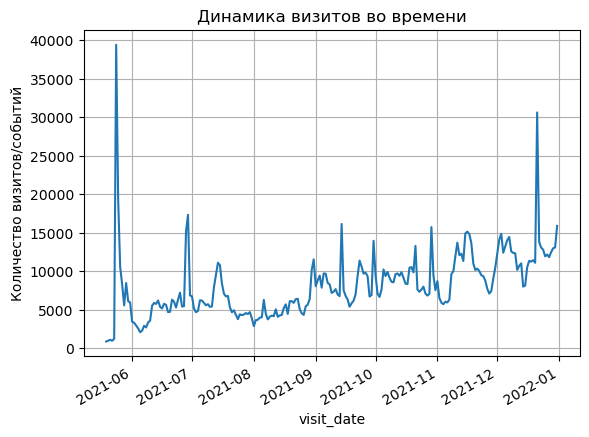

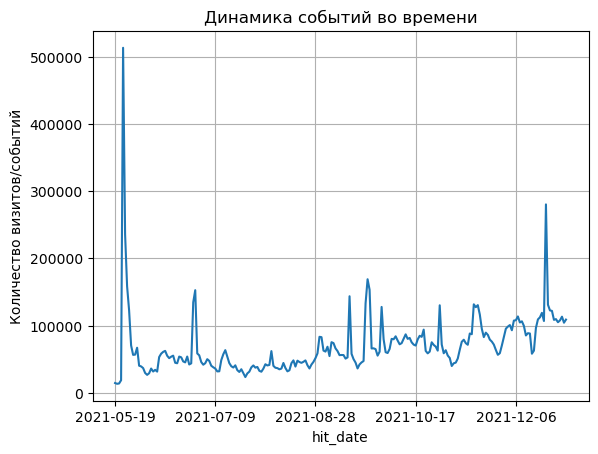

In [47]:
def plot_visits_over_time(df, column, title):
    df[column].value_counts().sort_index().plot(kind='line')
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Количество визитов/событий")
    plt.grid(True)
    plt.show()

plot_visits_over_time(df_combined, "visit_date", "Динамика визитов во времени")
plot_visits_over_time(df_hits, "hit_date", "Динамика событий во времени")

In [48]:
df_combined['visit_date'].value_counts(dropna=False)

visit_date
2021-05-24 00:00:00+00:00    39402
2021-12-21 00:00:00+00:00    30619
2021-05-25 00:00:00+00:00    19269
2021-06-29 00:00:00+00:00    17334
2021-09-14 00:00:00+00:00    16141
                             ...  
2021-06-05 00:00:00+00:00     2090
2021-05-23 00:00:00+00:00     1232
2021-05-21 00:00:00+00:00     1100
2021-05-22 00:00:00+00:00      984
2021-05-19 00:00:00+00:00      877
Name: count, Length: 226, dtype: int64

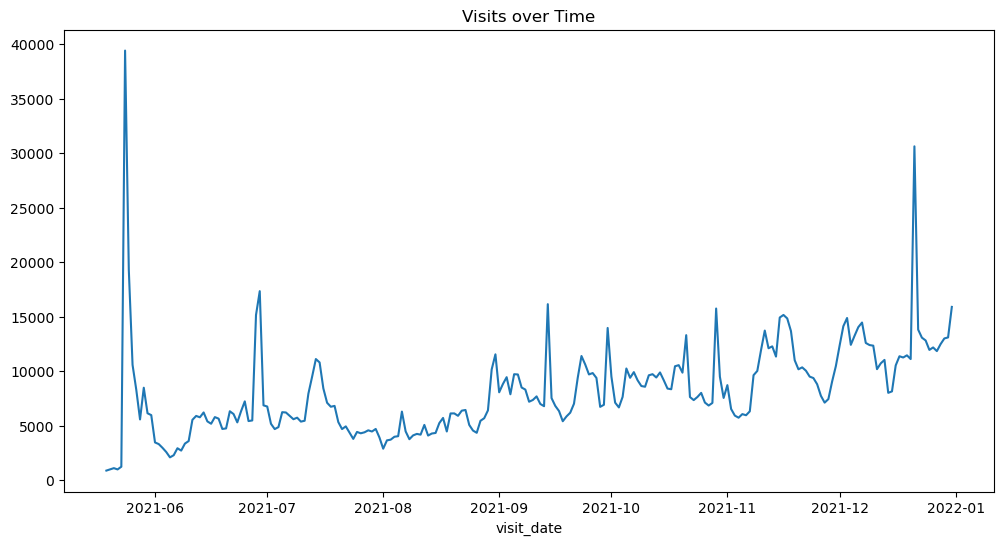

In [49]:
#Распределение visit_date по дням
df_combined['visit_date'].dt.date.value_counts().sort_index().plot(kind='line', figsize=(12, 6))
plt.title('Visits over Time')
plt.show()

In [50]:
# Группируем по дате и считаем количество визитов
visit_counts = df_combined.groupby('visit_date')['visit_date'].count()
visit_counts.name = 'count'
visit_counts = visit_counts.reset_index()


# Вычисляем IQR
Q1 = visit_counts['count'].quantile(0.25)
Q3 = visit_counts['count'].quantile(0.75)
IQR = Q3 - Q1

# Определяем границы
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Выделяем выбросы
outliers = visit_counts[(visit_counts['count'] < lower_bound) | (visit_counts['count'] > upper_bound)]
normal_data = visit_counts[(visit_counts['count'] >= lower_bound) & (visit_counts['count'] <= upper_bound)]
# Выводим дни и значения выбросов
print(outliers[['visit_date', 'count']])


                   visit_date  count
4   2021-05-24 00:00:00+00:00  39402
5   2021-05-25 00:00:00+00:00  19269
215 2021-12-21 00:00:00+00:00  30619


In [51]:
df_filtered = df_combined[~df_combined['visit_date'].isin(outliers['visit_date'])]

df_filtered

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,1000009318903347362.1632663668.1632663668,0,232832813.163266,2021-09-26 00:00:00+00:00,1900-01-01 16:00:00+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Chrome,Russia,Gelendzhik
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23 00:00:00+00:00,1900-01-01 21:24:03+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh
2,1000013386240115915.1635402956.1635402956,0,232833760.16354,2021-10-28 00:00:00+00:00,1900-01-01 09:35:56+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,412x846,Chrome,Russia,Cherkessk
3,1000017303238376207.1623489300.1623489300,0,232834672.162349,2021-06-12 00:00:00+00:00,1900-01-01 12:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Realme,other,360x780,Chrome,Russia,Irkutsk
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 08:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0,23282272.162681,2021-07-20 00:00:00+00:00,1900-01-01 23:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x667,Safari,Russia,Saint Petersburg
1860038,999966717128502952.1638428330.1638428330,0,232822894.163843,2021-12-02 00:00:00+00:00,1900-01-01 09:58:50+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x873,Chrome,Russia,Nizhny Novgorod
1860039,999969216784562223.1623521327.1623521327,0,232823476.162352,2021-06-12 00:00:00+00:00,1900-01-01 21:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,Safari,Russia,Moscow
1860040,999988617151873171.1623556243.1623556243,0,232827993.162356,2021-06-13 00:00:00+00:00,1900-01-01 06:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x732,Samsung Internet,Russia,Chelyabinsk


/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_29445/2901829424.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')
/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_29445/2901829424.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')


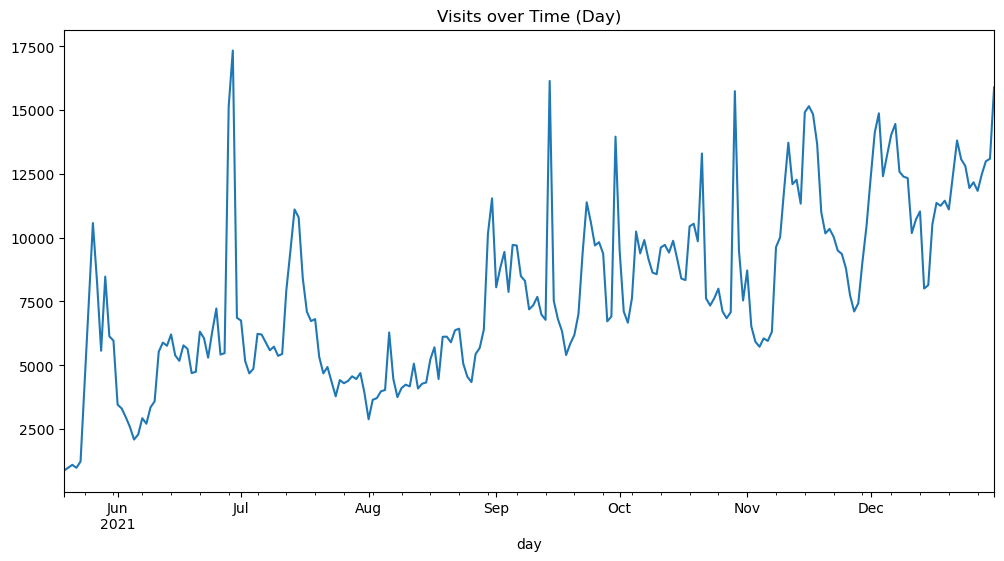

count      223.000000
mean      7889.349776
std       3384.928850
min        877.000000
25%       5430.500000
50%       7192.000000
75%      10163.000000
max      17334.000000
Name: count, dtype: float64
Series([], Freq: D, Name: count, dtype: int64)


In [52]:
# Группируем данные по году и месяцу, чтобы найти аномалии
df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')

# Считаем количество визитов в каждом дне
visit_counts = df_filtered['day'].value_counts().sort_index()

# Строим график
visit_counts.plot(kind='line', figsize=(12, 6))
plt.title('Visits over Time (Day)')
plt.show()

print(visit_counts.describe())

# Найдем выбросы на основе количества визитов
mean_visits = visit_counts.mean()
std_visits = visit_counts.std()

outliers = visit_counts[visit_counts > mean_visits + 3 * std_visits]

print(outliers)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


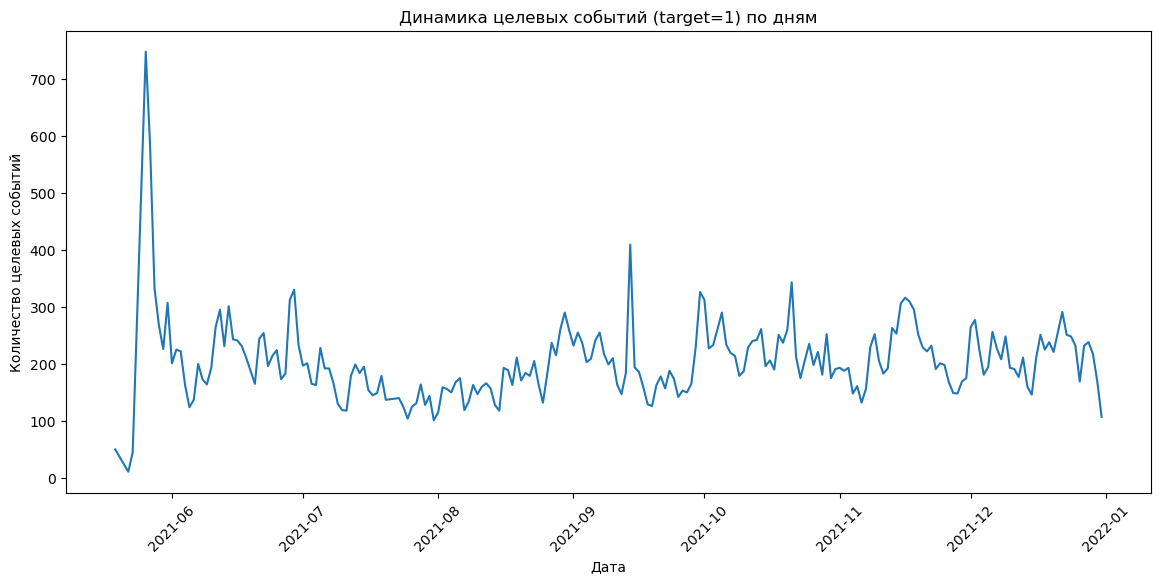

In [53]:
# Динамика целевых событий (target=1) по дням
target_counts = df_filtered[df_filtered['target'] == 1].groupby('visit_date').size().reset_index(name='target_count')
plt.figure(figsize=(14, 6))
sns.lineplot(data=target_counts, x='visit_date', y='target_count')
plt.title('Динамика целевых событий (target=1) по дням')
plt.xlabel('Дата')
plt.ylabel('Количество целевых событий')
plt.xticks(rotation=45)
plt.show()


In [54]:
# Статистика для определения выбросов
mean_target_count = target_counts['target_count'].mean()
std_target_count = target_counts['target_count'].std()

outliers_target = target_counts[target_counts['target_count'] > mean_target_count + 3 * std_target_count]
print("Аномальные дни с высоким количеством целевых событий:")
print(outliers)

Аномальные дни с высоким количеством целевых событий:
Series([], Freq: D, Name: count, dtype: int64)


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


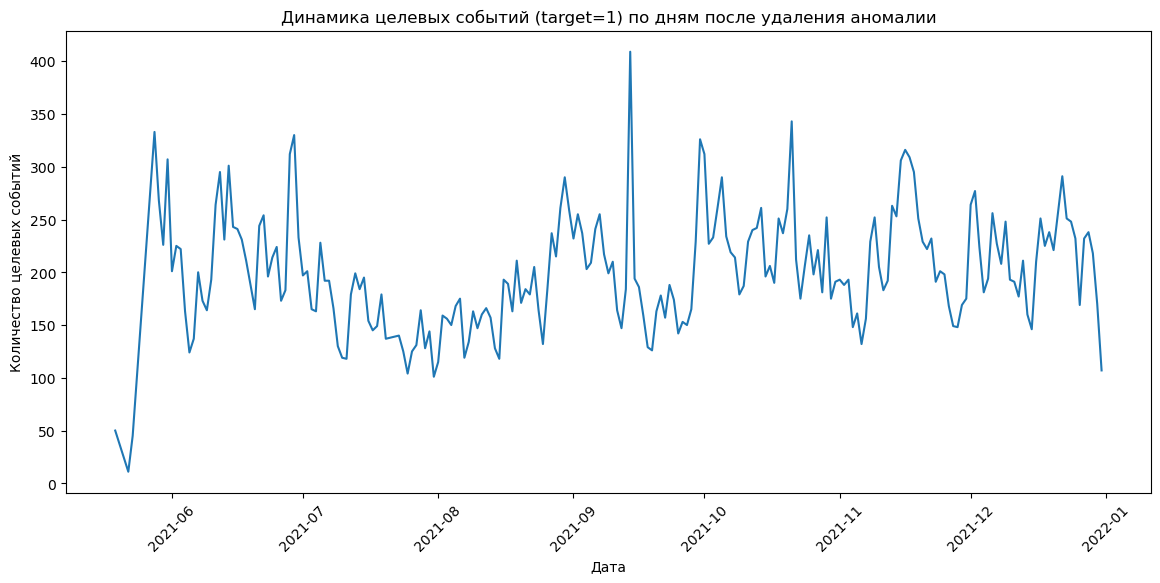


Статистика целевых событий после удаления аномалии:
count    220.000000
mean     199.363636
std       55.344703
min       11.000000
25%      163.000000
50%      193.500000
75%      232.250000
max      409.000000
Name: target_count, dtype: float64

Оставшиеся аномалии (если есть):
                   visit_date  target_count
112 2021-09-14 00:00:00+00:00           409


In [55]:
# Удаление строк за аномальный день
df_filtered = df_filtered[~df_filtered['visit_date'].isin(outliers_target['visit_date'])]

# Проверка результата: пересчет динамики целевых событий
target_counts_new = df_filtered[df_filtered['target'] == 1].groupby('visit_date').size().reset_index(name='target_count')
plt.figure(figsize=(14, 6))
sns.lineplot(data=target_counts_new, x='visit_date', y='target_count')
plt.title('Динамика целевых событий (target=1) по дням после удаления аномалии')
plt.xlabel('Дата')
plt.ylabel('Количество целевых событий')
plt.xticks(rotation=45)
plt.show()

# Новая статистика
print("\nСтатистика целевых событий после удаления аномалии:")
print(target_counts_new['target_count'].describe())

# Проверка оставшихся аномалий
mean_target_count_new = target_counts_new['target_count'].mean()
std_target_count_new = target_counts_new['target_count'].std()
outliers_new = target_counts_new[target_counts_new['target_count'] > mean_target_count_new + 3 * std_target_count_new]
print("\nОставшиеся аномалии (если есть):")
print(outliers_new if not outliers_new.empty else "Нет аномалий")

оставшиеся аномалии не будем удалять, иначе у нас не останется совсем примеров положительных целевых значений

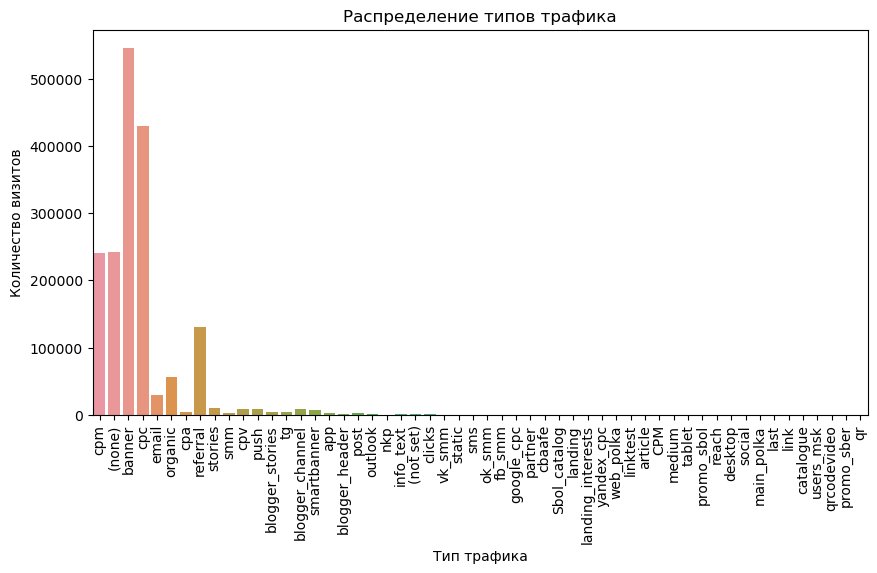

In [57]:
plt.figure(figsize=(10, 5))
sns.countplot(x="utm_medium", data=df_filtered)
plt.title("Распределение типов трафика")
plt.xlabel("Тип трафика")
plt.xticks(rotation=90)
plt.ylabel("Количество визитов")
plt.show()

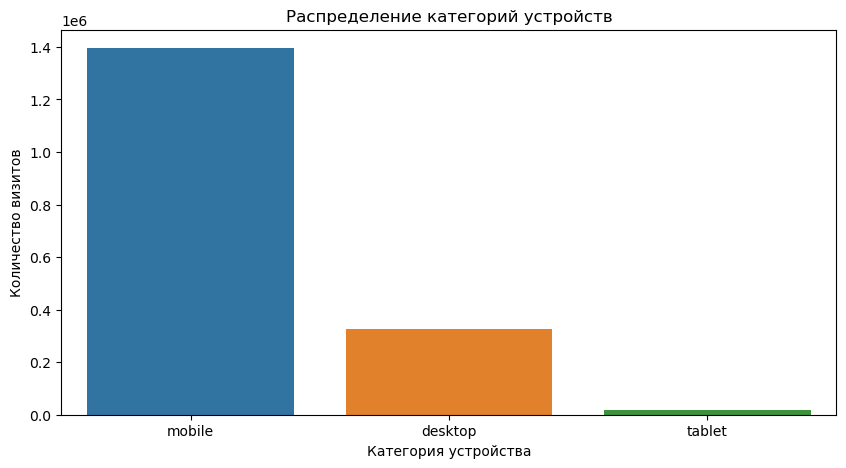

In [58]:
plt.figure(figsize=(10, 5))
sns.countplot(x="device_category", data=df_filtered)
plt.title("Распределение категорий устройств")
plt.xlabel("Категория устройства")
plt.ylabel("Количество визитов")
plt.show()

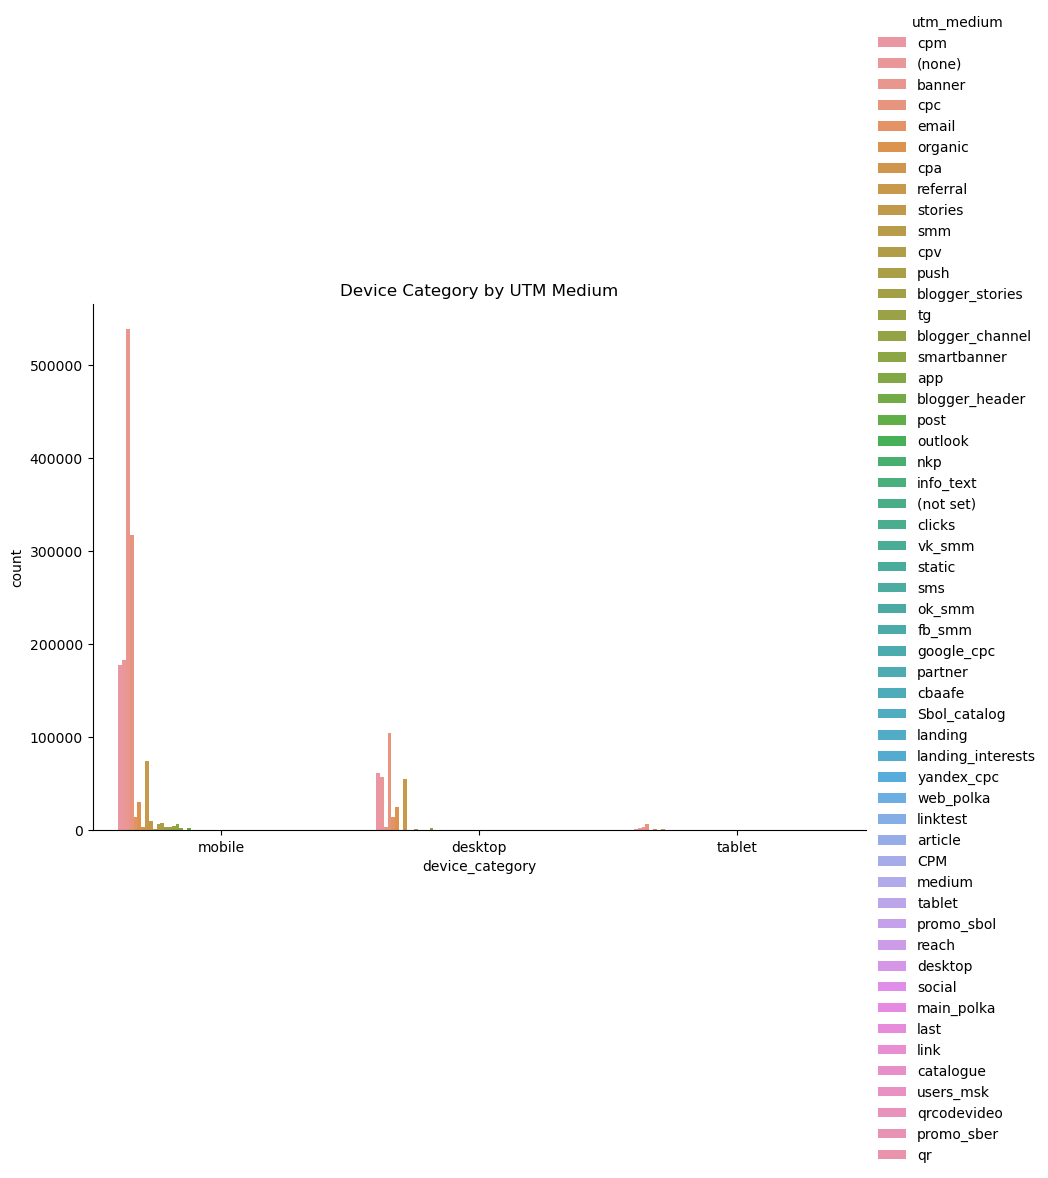

In [59]:
sns.catplot(data=df_filtered, x='device_category', hue='utm_medium', kind='count', height=6, aspect=1.5)
plt.title('Device Category by UTM Medium')
plt.show()

на мобильных устройствах больше просматриваются баннеры, а на десктопах - cpc

In [61]:
# Фильтруем строки, где utm_medium == '(none)'
filtered_data = df_filtered[df_filtered['utm_medium'] == '(none)']

# Выводим уникальные значения visit_date для этих строк
print(filtered_data['visit_date'].unique())

<DatetimeArray>
['2021-10-23 00:00:00+00:00', '2021-06-29 00:00:00+00:00',
 '2021-11-29 00:00:00+00:00', '2021-07-05 00:00:00+00:00',
 '2021-11-17 00:00:00+00:00', '2021-06-26 00:00:00+00:00',
 '2021-11-10 00:00:00+00:00', '2021-05-28 00:00:00+00:00',
 '2021-06-19 00:00:00+00:00', '2021-09-05 00:00:00+00:00',
 ...
 '2021-06-24 00:00:00+00:00', '2021-11-19 00:00:00+00:00',
 '2021-11-30 00:00:00+00:00', '2021-12-16 00:00:00+00:00',
 '2021-12-14 00:00:00+00:00', '2021-12-22 00:00:00+00:00',
 '2021-06-12 00:00:00+00:00', '2021-10-14 00:00:00+00:00',
 '2021-12-20 00:00:00+00:00', '2021-05-23 00:00:00+00:00']
Length: 221, dtype: datetime64[ns, UTC]


In [62]:
# Считаем количество строк, где utm_medium == '(none)'
count_none = df_filtered[df_filtered['utm_medium'] == '(none)'].shape[0]

# Считаем общее количество строк в DataFrame
total_count = df_filtered.shape[0]

# Рассчитываем процент
percentage_none = (count_none / total_count) * 100

print(f"Процент строк с utm_medium == '(none)': {percentage_none:.2f}%")


Процент строк с utm_medium == '(none)': 13.95%


In [63]:
df_filtered[df_filtered['utm_medium'] == '(none)']

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,day
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23 00:00:00+00:00,1900-01-01 21:24:03+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh,2021-10-23
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 08:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow,2021-06-29
5,1000020580299877109.1624972957.1624972957,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 16:00:00+00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow,2021-06-29
6,1000020580299877109.1624980453.1624980453,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 18:00:00+00:00,3,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,414x736,Safari,Russia,Moscow,2021-06-29
12,1000043953525145011.1638186424.1638186424,0,232840877.163819,2021-11-29 00:00:00+00:00,1900-01-01 14:47:04+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x851,YaBrowser,Russia,Moscow,2021-11-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1859973,999719769391513430.1636056921.1636056921,0,232765397.163606,2021-11-04 00:00:00+00:00,1900-01-01 23:15:21+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,Linux,other,other,2000x2000,Chrome,United States,Altoona,2021-11-04
1859988,99980178782731106.1626127202.1626127202,0,23278449.162613,2021-07-13 00:00:00+00:00,1900-01-01 01:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,YaBrowser,Russia,Moscow,2021-07-13
1859989,99980178782731106.1626182401.1626182401,0,23278449.162613,2021-07-13 00:00:00+00:00,1900-01-01 16:00:00+00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,YaBrowser,Russia,Moscow,2021-07-13
1859990,99980178782731106.1626284191.1626284191,0,23278449.162613,2021-07-14 00:00:00+00:00,1900-01-01 20:00:00+00:00,3,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,375x812,YaBrowser,Russia,Moscow,2021-07-14


In [64]:
df_source = df_filtered[df_filtered['utm_source'] == 'fDLlAcSmythWSCVMvqvL']

columns_of_interest = ['utm_medium', 'utm_campaign', 'utm_adcontent']
for column in columns_of_interest:
    unique_values = df_source[column].unique()
    print(f"Уникальные значения в столбце '{column}':")
    print(unique_values)
    print("-" * 50)

Уникальные значения в столбце 'utm_medium':
['(none)']
--------------------------------------------------
Уникальные значения в столбце 'utm_campaign':
['LTuZkdKfxRGVceoWkVyg']
--------------------------------------------------
Уникальные значения в столбце 'utm_adcontent':
['JNHcPlZPxEMWDnRiyoBf']
--------------------------------------------------


тк (none) относится к конкретным utm_source utm_campaign utm_adcontent - будем считать ее отдельным значчением и не заменять на самое популярное значение

In [66]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 20 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   target                    int64              
 2   client_id                 object             
 3   visit_date                datetime64[ns, UTC]
 4   visit_time                datetime64[ns, UTC]
 5   visit_number              int64              
 6   utm_source                object             
 7   utm_medium                object             
 8   utm_campaign              object             
 9   utm_adcontent             object             
 10  utm_keyword               object             
 11  device_category           object             
 12  device_os                 object             
 13  device_brand              object             
 14  device_model              object             
 15  device_screen_resolu

In [67]:
df_filtered.describe()

,target,visit_number
count,1.740474e+06,1.740474e+06
mean,2.520003e-02,2.088530e+00
std,1.567323e-01,5.126572e+00
min,0.000000e+00,1.000000e+00
25%,0.000000e+00,1.000000e+00
50%,0.000000e+00,1.000000e+00
75%,0.000000e+00,2.000000e+00
max,1.000000e+00,3.570000e+02


In [68]:
df_filtered['geo_country'].value_counts(dropna=False)

geo_country
Russia                  1684646
United States             11434
Ukraine                    8457
Ireland                    4022
Belarus                    3454
                         ...   
Barbados                      1
Puerto Rico                   1
Chad                          1
North Korea                   1
Bosnia & Herzegovina          1
Name: count, Length: 164, dtype: int64

In [69]:
df_filtered['geo_city'].value_counts(dropna=False)

geo_city
Moscow              744166
Saint Petersburg    279794
(not set)            74823
Yekaterinburg        33835
Krasnodar            30734
                     ...  
Shpola                   1
Leopoldshohe             1
Portimao                 1
Schwabisch Gmund         1
Detmold                  1
Name: count, Length: 2457, dtype: int64

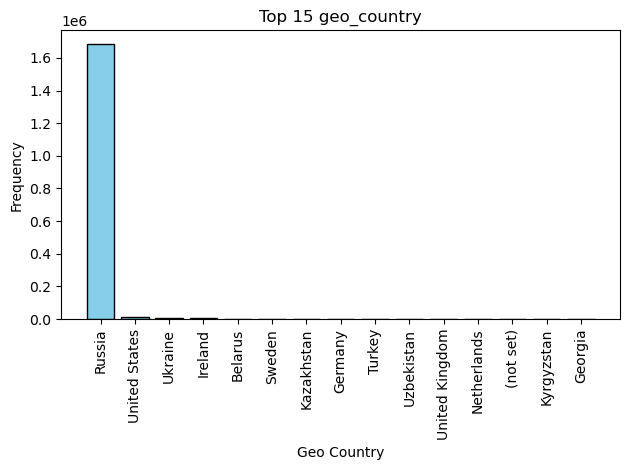

In [70]:
top_15_countries = df_filtered['geo_country'].value_counts().head(15)

plt.bar(top_15_countries.index, top_15_countries.values, color='skyblue', edgecolor='black')
plt.title('Top 15 geo_country')
plt.xlabel('Geo Country')
plt.ylabel('Frequency')
plt.xticks(rotation=90)  
plt.tight_layout()  
plt.show()

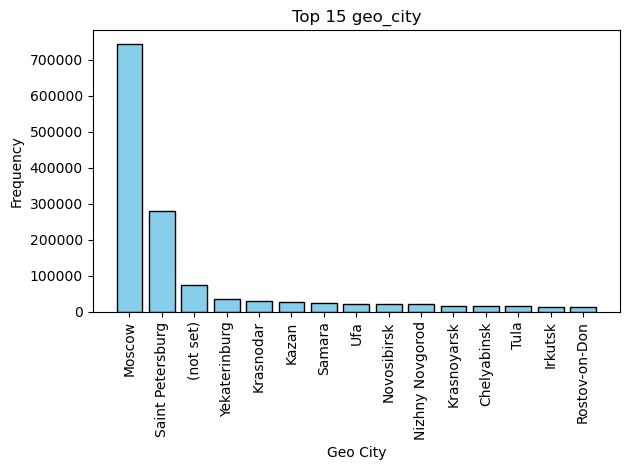

In [71]:
top_15_cities = df_filtered['geo_city'].value_counts().head(15)

plt.bar(top_15_cities.index, top_15_cities.values, color='skyblue', edgecolor='black')
plt.title('Top 15 geo_city')
plt.xlabel('Geo City')
plt.ylabel('Frequency')
plt.xticks(rotation=90)  
plt.tight_layout()  
plt.show()

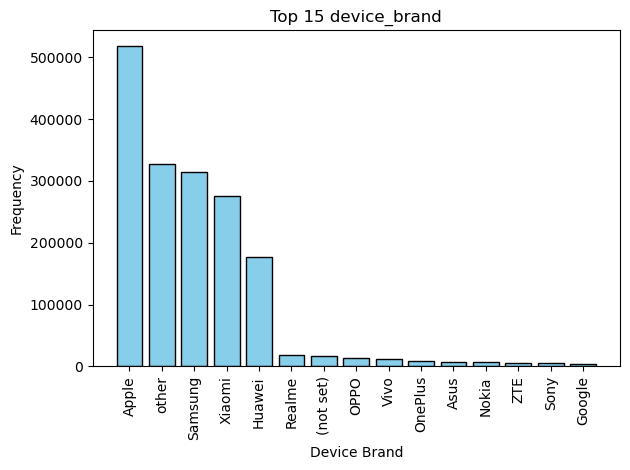

In [72]:
top_15_device_brand = df_filtered['device_brand'].value_counts().head(15)

plt.bar(top_15_device_brand.index, top_15_device_brand.values, color='skyblue', edgecolor='black')
plt.title('Top 15 device_brand')
plt.xlabel('Device Brand')
plt.ylabel('Frequency')
plt.xticks(rotation=90) 
plt.tight_layout()  
plt.show()

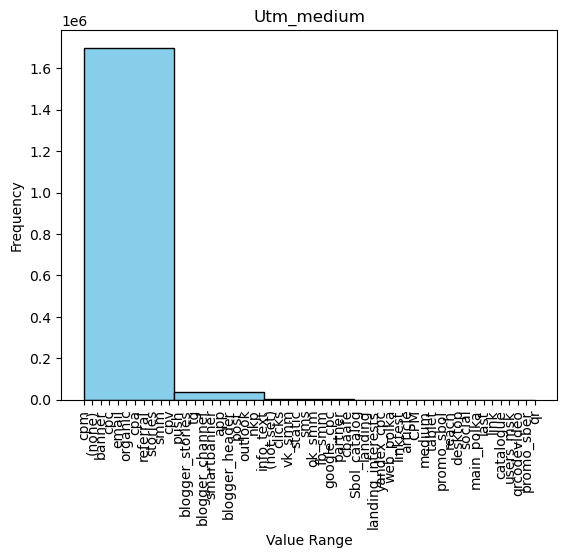

In [73]:
plt.hist(data = df_filtered, x = 'utm_medium', bins=5, color='skyblue', edgecolor='black')
plt.title('Utm_medium')
plt.xlabel('Value Range')
plt.xticks(rotation=90)
plt.ylabel('Frequency')
plt.show()

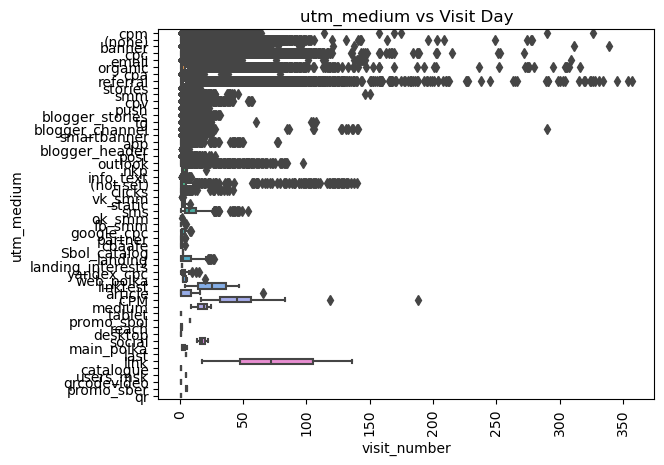

In [74]:
sns.boxplot(data=df_filtered, x='visit_number', y=df_filtered['utm_medium'])
plt.title('utm_medium vs Visit Day')
plt.xticks(rotation=90)  
plt.show()

In [75]:
# Удаление колонки day
df_filtered = df_filtered.drop(columns=['day'])
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   target                    int64              
 2   client_id                 object             
 3   visit_date                datetime64[ns, UTC]
 4   visit_time                datetime64[ns, UTC]
 5   visit_number              int64              
 6   utm_source                object             
 7   utm_medium                object             
 8   utm_campaign              object             
 9   utm_adcontent             object             
 10  utm_keyword               object             
 11  device_category           object             
 12  device_os                 object             
 13  device_brand              object             
 14  device_model              object             
 15  device_screen_resolu

In [76]:
# Извлекаем только время из visit_time
df_filtered['time_only'] = df_filtered['visit_time'].dt.time

# Создаем функцию для определения временного интервала
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'morning'
    elif 12 <= hour < 17:
        return 'day'
    elif 17 <= hour < 22:
        return 'evening'
    else:
        return 'night'

# Добавляем новую колонку с обозначением временного интервала
df_filtered['time_period'] = df_filtered['visit_time'].dt.hour.apply(get_time_period)

print(df_filtered[['visit_time', 'time_only', 'time_period']].head())


                 visit_time time_only time_period
0 1900-01-01 16:00:00+00:00  16:00:00         day
1 1900-01-01 21:24:03+00:00  21:24:03     evening
2 1900-01-01 09:35:56+00:00  09:35:56     morning
3 1900-01-01 12:00:00+00:00  12:00:00         day
4 1900-01-01 08:00:00+00:00  08:00:00     morning


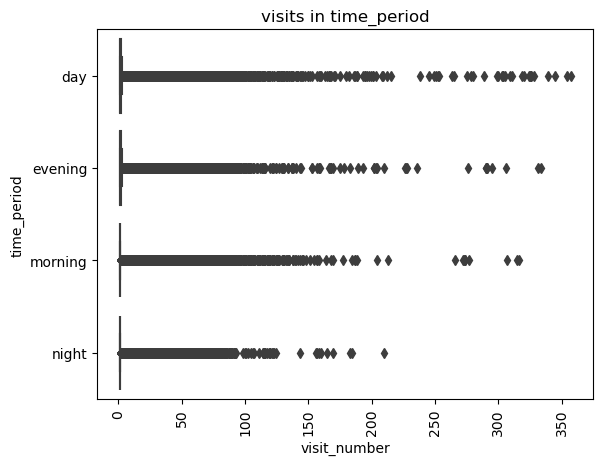

In [77]:
sns.boxplot(data=df_filtered, x='visit_number', y=df_filtered['time_period'])
plt.title('visits in time_period')
plt.xticks(rotation=90)  
plt.show()

In [78]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   target                    int64              
 2   client_id                 object             
 3   visit_date                datetime64[ns, UTC]
 4   visit_time                datetime64[ns, UTC]
 5   visit_number              int64              
 6   utm_source                object             
 7   utm_medium                object             
 8   utm_campaign              object             
 9   utm_adcontent             object             
 10  utm_keyword               object             
 11  device_category           object             
 12  device_os                 object             
 13  device_brand              object             
 14  device_model              object             
 15  device_screen_resolu

In [79]:
# Создаём новую колонку с названием дня недели
df_filtered['day_of_week'] = df_filtered['visit_date'].dt.day_name()

print(df_filtered[['visit_date', 'day_of_week']].head())


                 visit_date day_of_week
0 2021-09-26 00:00:00+00:00      Sunday
1 2021-10-23 00:00:00+00:00    Saturday
2 2021-10-28 00:00:00+00:00    Thursday
3 2021-06-12 00:00:00+00:00    Saturday
4 2021-06-29 00:00:00+00:00     Tuesday


/opt/anaconda3/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


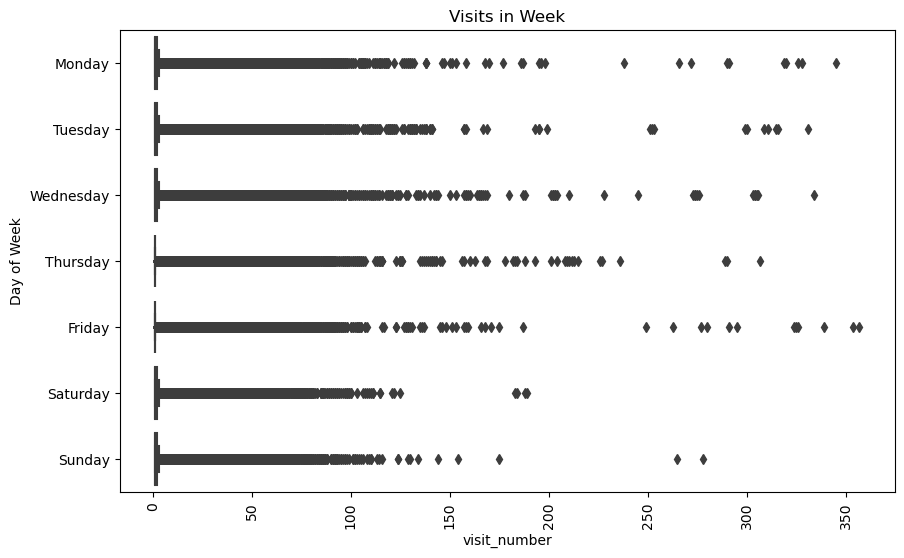

In [80]:
# Устанавливаем порядок дней недели
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Преобразуем столбец day_of_week в категориальный тип с заданным порядком
df_filtered['day_of_week'] = pd.Categorical(df_filtered['day_of_week'], categories=days_order, ordered=True)

# Создаём boxplot с упорядоченными днями недели
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_filtered, x='visit_number', y='day_of_week')
plt.title('Visits in Week')
plt.xticks(rotation=90)
plt.ylabel('Day of Week')  
plt.show()


In [81]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 22 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   target                    int64              
 2   client_id                 object             
 3   visit_date                datetime64[ns, UTC]
 4   visit_time                datetime64[ns, UTC]
 5   visit_number              int64              
 6   utm_source                object             
 7   utm_medium                object             
 8   utm_campaign              object             
 9   utm_adcontent             object             
 10  utm_keyword               object             
 11  device_category           object             
 12  device_os                 object             
 13  device_brand              object             
 14  device_model              object             
 15  device_screen_resolu

In [82]:
df_filtered.head()

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,...,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,time_only,time_period,day_of_week
0,1000009318903347362.1632663668.1632663668,0,232832813.163266,2021-09-26 00:00:00+00:00,1900-01-01 16:00:00+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,...,other,Samsung,other,412x869,Chrome,Russia,Gelendzhik,16:00:00,day,Sunday
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23 00:00:00+00:00,1900-01-01 21:24:03+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,...,Android,Samsung,other,360x640,Samsung Internet,Russia,Voronezh,21:24:03,evening,Saturday
2,1000013386240115915.1635402956.1635402956,0,232833760.16354,2021-10-28 00:00:00+00:00,1900-01-01 09:35:56+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,...,Android,Samsung,other,412x846,Chrome,Russia,Cherkessk,09:35:56,morning,Thursday
3,1000017303238376207.1623489300.1623489300,0,232834672.162349,2021-06-12 00:00:00+00:00,1900-01-01 12:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,...,other,Realme,other,360x780,Chrome,Russia,Irkutsk,12:00:00,day,Saturday
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 08:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,...,other,Apple,other,414x736,Safari,Russia,Moscow,08:00:00,morning,Tuesday


In [83]:
# Выделяем необходимые атрибуты

df_filtered['month'] = df_filtered['visit_date'].dt.month
df_filtered['day'] = df_filtered['visit_date'].dt.day
df_filtered['day_of_week'] = df_filtered['visit_date'].dt.weekday  # 0 - понедельник, 6 - воскресенье
df_filtered['is_weekend'] = df_filtered['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)  # 1 - выходной, 0 - рабочий

df_filtered[['visit_date', 'month', 'day', 'day_of_week', 'is_weekend']].head()


,visit_date,month,day,day_of_week,is_weekend
0,2021-09-26 00:00:00+00:00,9,26,6,1
1,2021-10-23 00:00:00+00:00,10,23,5,1
2,2021-10-28 00:00:00+00:00,10,28,3,0
3,2021-06-12 00:00:00+00:00,6,12,5,1
4,2021-06-29 00:00:00+00:00,6,29,1,0


In [84]:
# Установка стиля для графиков
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [85]:
# Разделяем device_screen_resolution на width и height
df_filtered[['width', 'height']] = df_filtered['device_screen_resolution'].str.split('x', expand=True)

# Заменяем '(not set)' и другие некорректные значения на NaN
df_filtered['width'] = pd.to_numeric(df_filtered['width'], errors='coerce')
df_filtered['height'] = pd.to_numeric(df_filtered['height'], errors='coerce')

# Проверяем топ-10 значений для width
print(df_filtered['width'].value_counts().head(10))

# Заполняем NaN
df_filtered['width'] = df_filtered['width'].fillna(df_filtered['width'].median())
df_filtered['height'] = df_filtered['height'].fillna(df_filtered['height'].median())

# преобразуем после заполнения NaN
df_filtered['width'] = df_filtered['width'].astype(int)
df_filtered['height'] = df_filtered['height'].astype(int)

width
360.0     373748
375.0     200647
414.0     190118
393.0     186850
412.0     172661
1920.0    116316
320.0      68846
390.0      57663
428.0      38413
1536.0     34810
Name: count, dtype: int64


In [86]:
df_filtered['height'].value_counts().head(10)

height
896     159092
1080    117092
812     109670
851     109556
667      87865
780      87304
800      83972
640      75516
915      70332
720      66326
Name: count, dtype: int64

In [87]:
df_filtered.drop(columns=['device_screen_resolution'], inplace=True)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


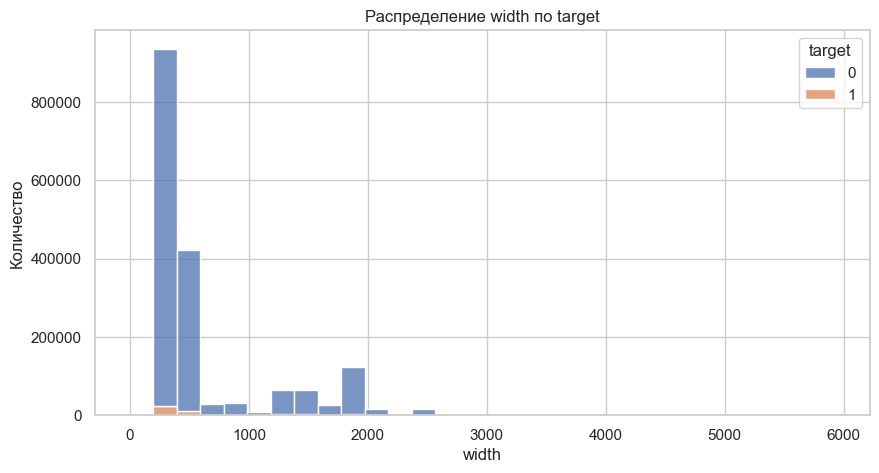

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


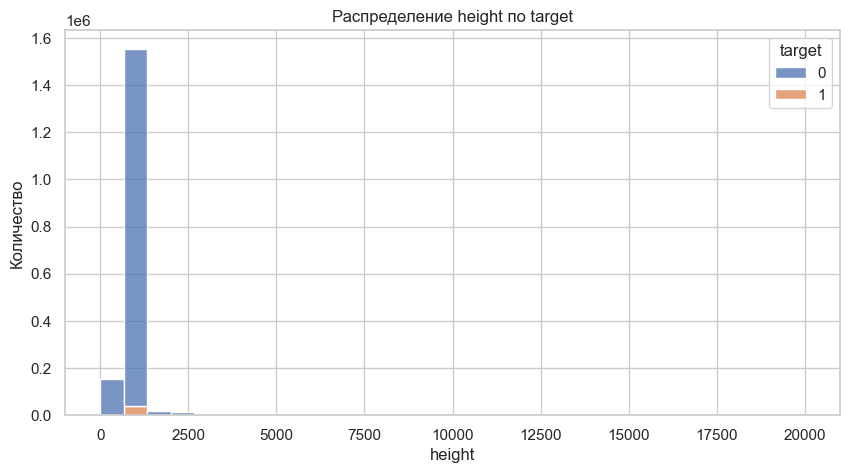

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


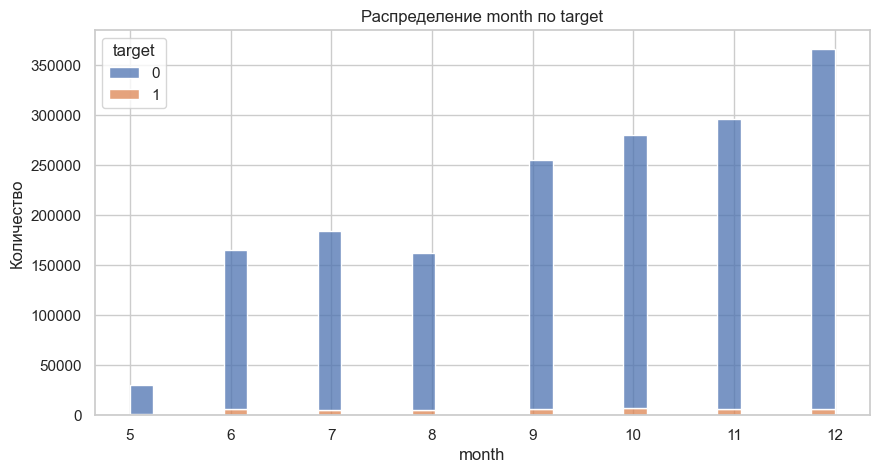

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


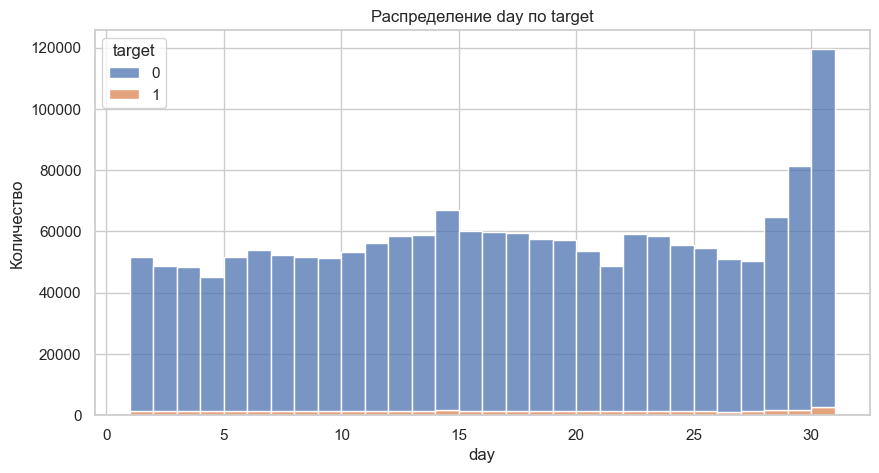

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


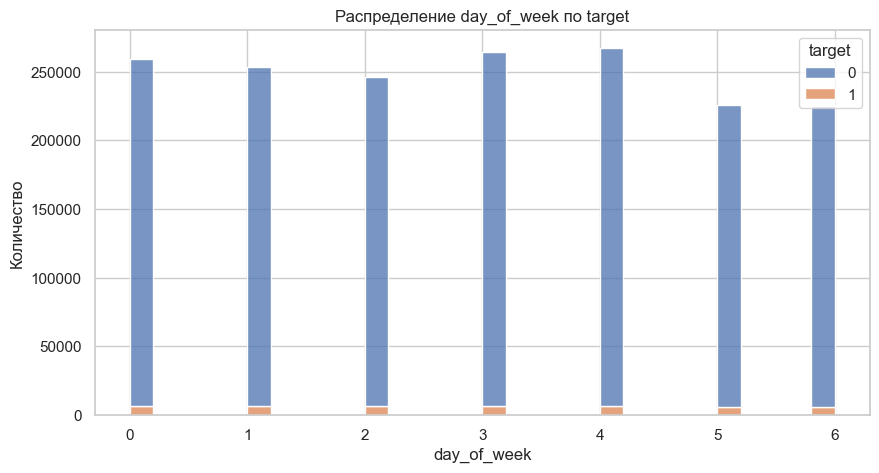

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


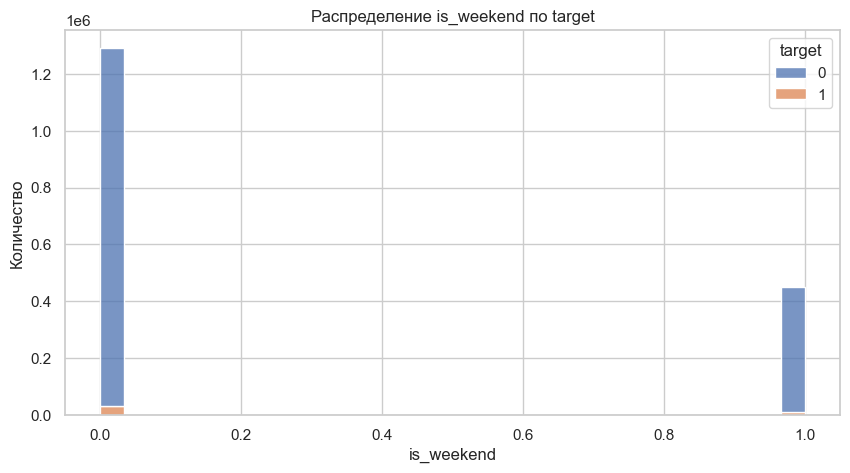

In [88]:
# Визуализация распределений
# Числовые признаки
numeric_cols = ['width', 'height', 'month', 'day', 'day_of_week', 'is_weekend']
categorical_cols = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_category', 'device_os', 'device_brand', 'device_model', 'device_browser',
    'geo_country', 'geo_city', 'time_period'
]

# Гистограммы для числовых признаков
for col in numeric_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df_filtered, x=col, hue='target', multiple='stack', bins=30)
    plt.title(f'Распределение {col} по target')
    plt.xlabel(col)
    plt.ylabel('Количество')
    plt.show()

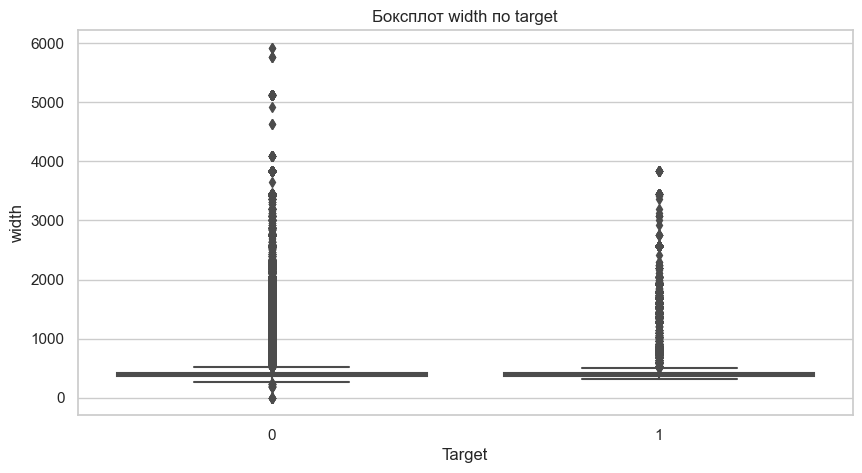

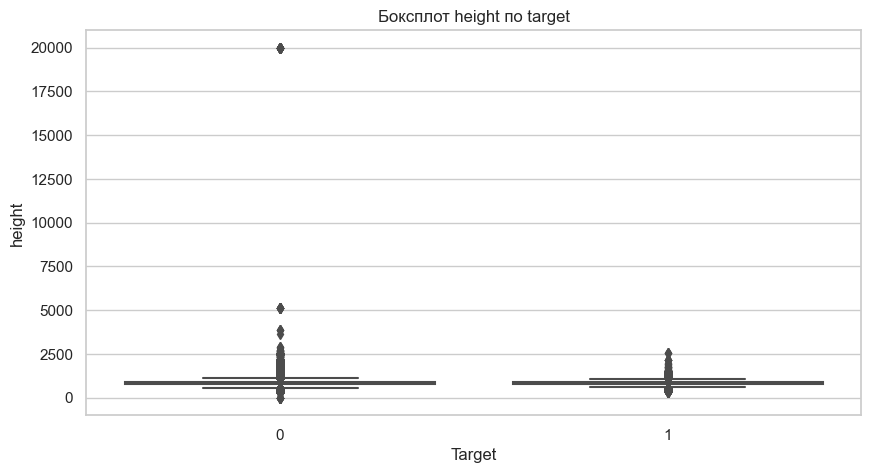

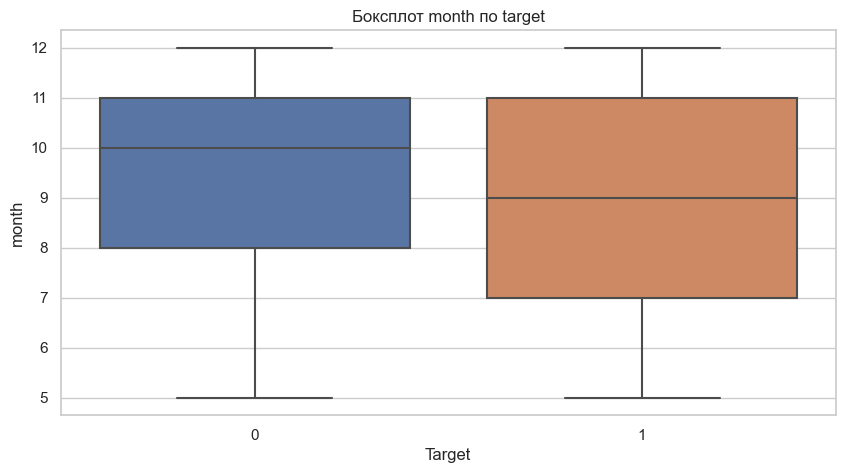

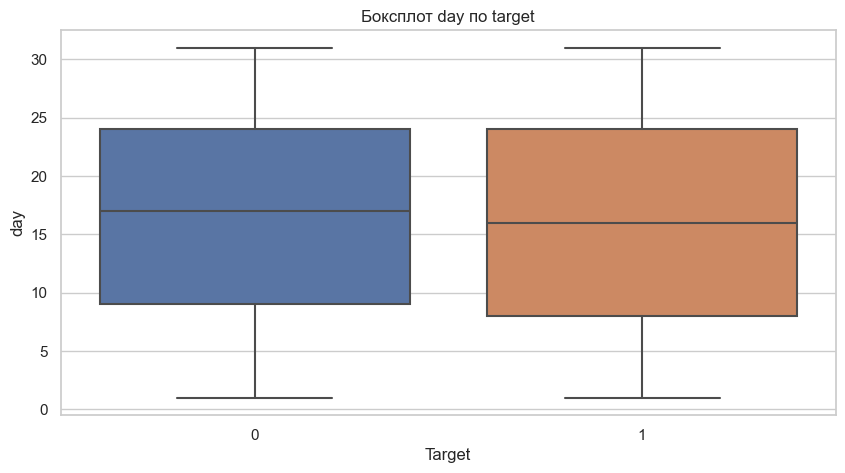

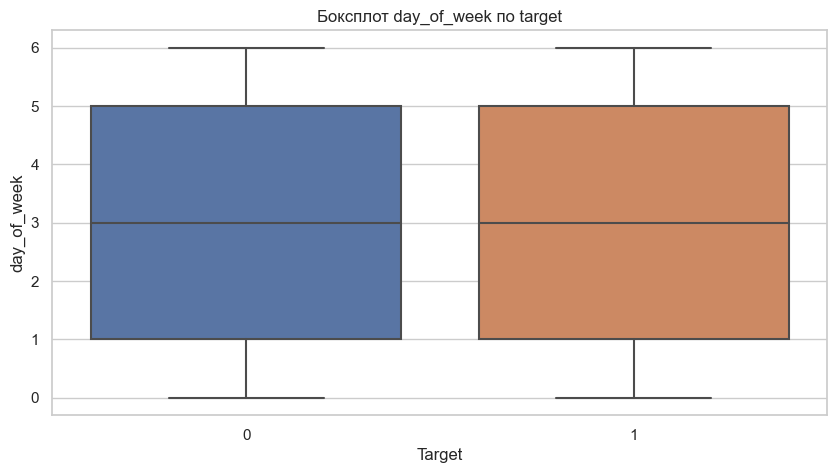

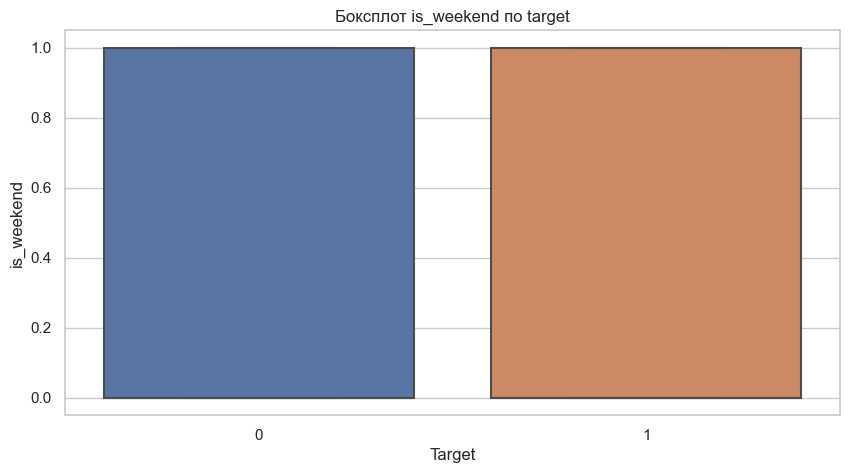

In [89]:
# Боксплоты для числовых признаков
for col in numeric_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_filtered, x='target', y=col)
    plt.title(f'Боксплот {col} по target')
    plt.xlabel('Target')
    plt.ylabel(col)
    plt.show()

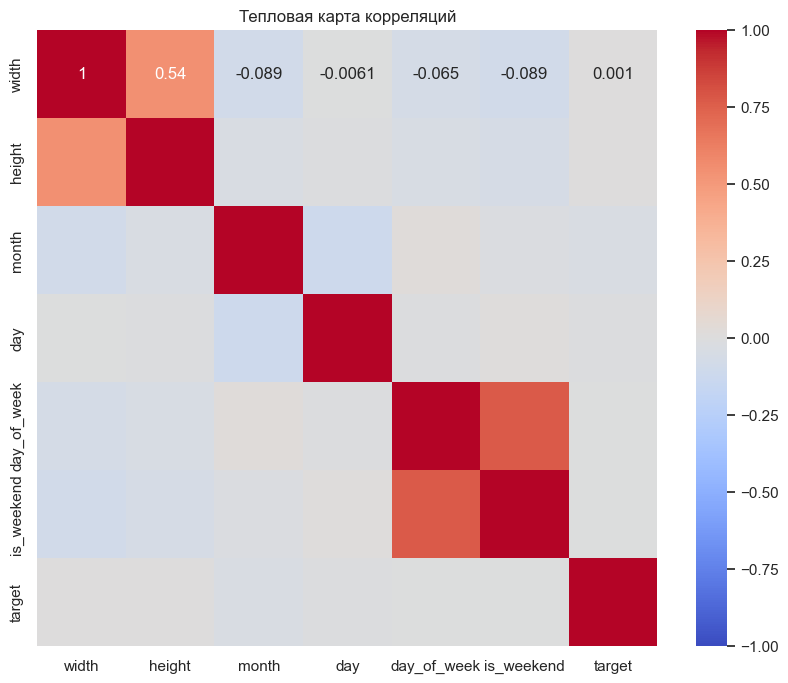

Основные корреляции с target:
target         1.000000
height         0.003829
width          0.001035
is_weekend    -0.002230
day_of_week   -0.004286
day           -0.008421
month         -0.038371
Name: target, dtype: float64


In [90]:
# Корреляции
# Выбираем числовые признаки и target
corr_cols = numeric_cols + ['target']
corr_matrix = df_filtered[corr_cols].corr()

# Построение тепловой карты
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Тепловая карта корреляций')
plt.show()

# Выводы по корреляциям
print("Основные корреляции с target:")
target_corr = corr_matrix['target'].sort_values(ascending=False)
print(target_corr)

## Подготовка датасета к обучению

In [92]:
df_filtered

,session_id,target,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,...,geo_country,geo_city,time_only,time_period,day_of_week,month,day,is_weekend,width,height
0,1000009318903347362.1632663668.1632663668,0,232832813.163266,2021-09-26 00:00:00+00:00,1900-01-01 16:00:00+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,...,Russia,Gelendzhik,16:00:00,day,6,9,26,1,412,869
1,1000010177899156286.1635013443.1635013443,0,232833013.163501,2021-10-23 00:00:00+00:00,1900-01-01 21:24:03+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,...,Russia,Voronezh,21:24:03,evening,5,10,23,1,360,640
2,1000013386240115915.1635402956.1635402956,0,232833760.16354,2021-10-28 00:00:00+00:00,1900-01-01 09:35:56+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,...,Russia,Cherkessk,09:35:56,morning,3,10,28,0,412,846
3,1000017303238376207.1623489300.1623489300,0,232834672.162349,2021-06-12 00:00:00+00:00,1900-01-01 12:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,...,Russia,Irkutsk,12:00:00,day,5,6,12,1,360,780
4,1000020580299877109.1624943350.1624943350,0,232835435.162494,2021-06-29 00:00:00+00:00,1900-01-01 08:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,...,Russia,Moscow,08:00:00,morning,1,6,29,0,414,736
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,99996598443387715.1626811203.1626811203,0,23282272.162681,2021-07-20 00:00:00+00:00,1900-01-01 23:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,...,Russia,Saint Petersburg,23:00:00,night,1,7,20,0,375,667
1860038,999966717128502952.1638428330.1638428330,0,232822894.163843,2021-12-02 00:00:00+00:00,1900-01-01 09:58:50+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,...,Russia,Nizhny Novgorod,09:58:50,morning,3,12,2,0,393,873
1860039,999969216784562223.1623521327.1623521327,0,232823476.162352,2021-06-12 00:00:00+00:00,1900-01-01 21:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,...,Russia,Moscow,21:00:00,evening,5,6,12,1,375,812
1860040,999988617151873171.1623556243.1623556243,0,232827993.162356,2021-06-13 00:00:00+00:00,1900-01-01 06:00:00+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,...,Russia,Chelyabinsk,06:00:00,morning,6,6,13,1,412,732


In [93]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   target           int64              
 2   client_id        object             
 3   visit_date       datetime64[ns, UTC]
 4   visit_time       datetime64[ns, UTC]
 5   visit_number     int64              
 6   utm_source       object             
 7   utm_medium       object             
 8   utm_campaign     object             
 9   utm_adcontent    object             
 10  utm_keyword      object             
 11  device_category  object             
 12  device_os        object             
 13  device_brand     object             
 14  device_model     object             
 15  device_browser   object             
 16  geo_country      object             
 17  geo_city         object             
 18  time_only        object             
 19  time_

In [94]:
df_filtered['target'].value_counts()

target
0    1696614
1      43860
Name: count, dtype: int64

In [95]:
df_filtered['utm_keyword'].value_counts().head(20)

utm_keyword
puhZPIYqKXeFPaUviSjo    1474284
aXQzDWsJuGXeBXexNHjc      23956
pHqgLcdBQPSLcrTpLkdr      13590
ITfrGJNwVsHBGJMAKoct      12511
hAmNSZmQkKQKAjZEGlgb      10849
UKNBOHebRIIsQRsjNKay      10383
IGUCNvHlhfHpROGclCit       7568
RkpOyeEPgcMBSDuHLQcj       6978
BmOOOIoWGHEfxEfoUezs       6601
JajANoFxoqXfKRNBUhzx       6462
ZNhSIPchlbnKwZWcsKzz       5618
pucKZkLDtpMDBTobJAJG       5391
YQXPpoLsxnykCWKhGEmI       4785
RrhnkuoaqckNtJpAZDzH       4700
DBHgBJHOdbPwsRDUbEgX       4470
XEayFbemrPYbxFeNbxif       3674
tVtbIKrPSOvrXLCznVVe       3572
MWLEpQPyjGkjHseVyeyQ       3052
fzbotReoFzSuckjwcpCs       2965
COtBsnAzfZyRVtvDlhnW       2785
Name: count, dtype: int64

In [96]:
top_keywords = df_filtered['utm_keyword'].value_counts().head(20).index
df_filtered['utm_keyword'] = df_filtered['utm_keyword'].apply(lambda x: x if x in top_keywords else 'other')
df_filtered['utm_keyword'].value_counts().head(20)

utm_keyword
puhZPIYqKXeFPaUviSjo    1474284
other                    126280
aXQzDWsJuGXeBXexNHjc      23956
pHqgLcdBQPSLcrTpLkdr      13590
ITfrGJNwVsHBGJMAKoct      12511
hAmNSZmQkKQKAjZEGlgb      10849
UKNBOHebRIIsQRsjNKay      10383
IGUCNvHlhfHpROGclCit       7568
RkpOyeEPgcMBSDuHLQcj       6978
BmOOOIoWGHEfxEfoUezs       6601
JajANoFxoqXfKRNBUhzx       6462
ZNhSIPchlbnKwZWcsKzz       5618
pucKZkLDtpMDBTobJAJG       5391
YQXPpoLsxnykCWKhGEmI       4785
RrhnkuoaqckNtJpAZDzH       4700
DBHgBJHOdbPwsRDUbEgX       4470
XEayFbemrPYbxFeNbxif       3674
tVtbIKrPSOvrXLCznVVe       3572
MWLEpQPyjGkjHseVyeyQ       3052
fzbotReoFzSuckjwcpCs       2965
Name: count, dtype: int64

In [97]:
top_utm_source = df_filtered['utm_source'].value_counts().head(20).index
df_filtered['utm_source'] = df_filtered['utm_source'].apply(lambda x: x if x in top_utm_source else 'other')
df_filtered['utm_source'].value_counts().head(20)

utm_source
ZpYIoDJMcFzVoPFsHGJL    552360
kjsLglQLzykiRbcDiGcD    257917
fDLlAcSmythWSCVMvqvL    242827
MvfHsxITijuriZxsqZqt    185075
BHcvLfOaCWvWTykYqHVe    114074
bByPQxmDaMXgpHeypKSM     90929
QxAxdyPLuQMEcrdZWdWb     50999
other                    45236
jaSOmLICuBzCFqHfBdRg     28696
RmEBuqrriAfAVsLQQmhk     28049
aXQzDWsJuGXeBXexNHjc     25163
vFcAhRxLfOWKhvxjELkx     24110
PlbkrSYoHuZBWfYjYnfw     20783
hTjLvqNxGggkGnxSCaTm     14449
gDBGzjFKYabGgSPZvrDH     13565
fgymSoTvjKPEgaIJqsiH      9624
geDcueAOghDzHkGMmdOq      8680
ISrKoXQCxqqYvAZICvjs      8521
nSReTmyFtbSjlPrTKoaX      7205
SzZERoLMmrEUEhDaYcyN      6826
Name: count, dtype: int64

In [98]:
top_adcontent = df_filtered['utm_adcontent'].value_counts().head(20).index
df_filtered['utm_adcontent'] = df_filtered['utm_adcontent'].apply(lambda x: x if x in top_adcontent else 'other')
df_filtered['utm_adcontent'].value_counts().head(20)

utm_adcontent
JNHcPlZPxEMWDnRiyoBf    1230175
vCIpmpaGBnIQhyYNkXqp     176253
xhoenQgDQsgfEPYNPwKO     111967
PkybGvWbaqORmxjNunqZ      60314
other                     34565
LLfCasrxQzJIyuldcuWy      23937
TuyPWsGQruPMpKvRxeBF      18189
UxrnyMlRBSOhOjytXnMG      13583
dUuXlWzvmhDSyclWRhNP      10280
yYdBRbPmBMUZHXwqGxNx       9699
WYLajZgbUhGimwBKDZUH       8610
SOkCdPxfUcZUzzOdgGES       6905
AdeErYgVTbRcAWtHrMHq       6391
nNqUcgFgcqQbTVSvgaHr       6181
aYAcKhelKzYpXrRYknSP       5090
XSkXBCPfnJjvxbfeewtd       4208
XKsYZiUFcdkUXQpoLKyS       4112
FkiRXDLOWtzVfvhEkhNo       2838
xnyHaukLtAvgViiZSyBC       2582
SAVVWaMghGnnvPOqMOIt       2500
Name: count, dtype: int64

In [99]:
top_model = df_filtered['device_model'].value_counts().head(20).index
df_filtered['device_model'] = df_filtered['device_model'].apply(lambda x: x if x in top_model else 'other')
df_filtered['device_model'].value_counts().head(20)

device_model
other                   1726743
AuMdmADEIoPXiWpTsBEj       9250
cwMJxNXiWUgMUxGiCTPs        640
tWBQlsvNfHxRUjaPAfhd        626
pTgAEPipQxDXCjPrJbHo        448
FJApgTrMAGHoxCxQVKws        359
tfPZFRbtlzEssBEesRwM        325
pcvPxfVFaAmhwFmvIeYd        321
aCLaTVQlHcXbUnQYQvIg        220
mzJXHtJPIOSHoHtgezIA        220
JAIKWwxRffFOXQcfGTVi        191
zFCiMWkbbAhTflrlLWnz        169
jXFxTkHxuiBKWOvUtsIa        160
mSVMBvlHFgftJaQAZEdp        139
AshpvdJdReafUzEMmWGr        128
IiVVIXFnNMwpBtuHILvS        125
DzXtLnggNbQSyyFLKlgY        111
QIRMJBHwssjlXzlheRfO        100
wsPZygnUifLMgkSEnWLj        100
qBRdfuuhOnnqwSqNiPOv         99
Name: count, dtype: int64

In [100]:
top_brand = df_filtered['device_brand'].value_counts().head(20).index
df_filtered['device_brand'] = df_filtered['device_brand'].apply(lambda x: x if x in top_brand else 'other')
df_filtered['device_brand'].value_counts().head(20)

device_brand
Apple        517795
other        342713
Samsung      313997
Xiaomi       274997
Huawei       177428
Realme        18185
(not set)     16684
OPPO          12921
Vivo          11331
OnePlus        9153
Asus           7438
Nokia          6897
ZTE            6170
Sony           5971
Google         4597
Meizu          3604
Lenovo         3027
Blackview      2659
Tecno          2594
LG             2313
Name: count, dtype: int64

In [101]:
top_browser = df_filtered['device_browser'].value_counts().head(20).index
df_filtered['device_browser'] = df_filtered['device_browser'].apply(lambda x: x if x in top_browser else 'other')
df_filtered['device_browser'].value_counts().head(20)

device_browser
Chrome                              949893
Safari                              447782
YaBrowser                           121292
Safari (in-app)                      67288
Android Webview                      54189
Samsung Internet                     44585
Opera                                23949
Firefox                              14590
Edge                                 14306
UC Browser                             835
Android Runtime                        392
Mozilla Compatible Agent               346
other                                  269
[FBAN                                  268
Instagram 208.0.0.32.135 Android       140
Instagram 209.0.0.21.119 Android       111
MRCHROME                                73
Android Browser                         45
Opera Mini                              44
Puffin                                  41
Name: count, dtype: int64

In [102]:
top_country = df_filtered['geo_country'].value_counts().head(20).index
df_filtered['geo_country'] = df_filtered['geo_country'].apply(lambda x: x if x in top_country else 'other')
df_filtered['geo_country'].value_counts().head(20)

geo_country
Russia            1684646
United States       11434
other                9825
Ukraine              8457
Ireland              4022
Belarus              3454
Sweden               2573
Kazakhstan           2150
Germany              1974
Turkey               1873
Uzbekistan           1455
United Kingdom       1329
Netherlands          1318
(not set)            1048
Kyrgyzstan            902
Georgia               874
France                717
Cyprus                670
Armenia               621
Finland               590
Name: count, dtype: int64

In [103]:
df_filtered['geo_city'].value_counts().head(20)

geo_city
Moscow              744166
Saint Petersburg    279794
(not set)            74823
Yekaterinburg        33835
Krasnodar            30734
Kazan                27925
Samara               23574
Ufa                  20735
Novosibirsk          20542
Nizhny Novgorod      20083
Krasnoyarsk          15738
Chelyabinsk          15233
Tula                 14510
Irkutsk              13151
Rostov-on-Don        13137
Grozny               12315
Balashikha           12063
Vladivostok          12002
Voronezh             10496
Yaroslavl             9293
Name: count, dtype: int64

In [104]:
top_cities = df_filtered['geo_city'].value_counts().head(20).index
df_filtered['geo_city'] = df_filtered['geo_city'].apply(lambda x: x if x in top_cities else 'other')
df_filtered['geo_city'].value_counts().head(20)

geo_city
Moscow              744166
other               336325
Saint Petersburg    279794
(not set)            74823
Yekaterinburg        33835
Krasnodar            30734
Kazan                27925
Samara               23574
Ufa                  20735
Novosibirsk          20542
Nizhny Novgorod      20083
Krasnoyarsk          15738
Chelyabinsk          15233
Tula                 14510
Irkutsk              13151
Rostov-on-Don        13137
Grozny               12315
Balashikha           12063
Vladivostok          12002
Voronezh             10496
Name: count, dtype: int64

In [105]:
df_filtered['utm_campaign'].value_counts().head(20)

utm_campaign
LTuZkdKfxRGVceoWkVyg    595125
LEoPHuyFvzoNfnzGgfcd    318741
FTjNLDyTrXaWYgZymFkV    246252
gecBYcKZCPMcVYdSSzKP    133967
TmThBvoCcwkCZZUWACYq     26591
okTXSMadDkjvntEHzIjp     24208
XHNUiSKKGTEpSAlaVMFQ     23667
SgIUDYUKnyWHVowUOqid     22827
LwJZxKuWmvOhPsaCeRjG     17585
RoDitORHdzGfGhNCyEMy     15672
bxOTvPtyGSdUrbwoXCPO     15411
bJJuEXRheRIxXEaYIXqM     12207
YCKgTzTDywjcWyQudGch     11786
zxoiLxhuSIFrCeTLQVWZ     11634
nSReTmyFtbSjlPrTKoaX     11372
QEejXfOCtOMFLZqIPApp     10123
vRLTQQKAsFQMxbcHGPhu      9452
jvsVVQVKRfBIqBDBuCkq      7853
eimRuUrNhZLAYcwRrNXu      7672
VBmazutCflYumtDHrQYe      7466
Name: count, dtype: int64

In [106]:
top_campaign = df_filtered['utm_campaign'].value_counts().head(20).index
df_filtered['utm_campaign'] = df_filtered['utm_campaign'].apply(lambda x: x if x in top_campaign else 'other')
df_filtered['utm_campaign'].value_counts().head(20)

utm_campaign
LTuZkdKfxRGVceoWkVyg    595125
LEoPHuyFvzoNfnzGgfcd    318741
FTjNLDyTrXaWYgZymFkV    246252
other                   210863
gecBYcKZCPMcVYdSSzKP    133967
TmThBvoCcwkCZZUWACYq     26591
okTXSMadDkjvntEHzIjp     24208
XHNUiSKKGTEpSAlaVMFQ     23667
SgIUDYUKnyWHVowUOqid     22827
LwJZxKuWmvOhPsaCeRjG     17585
RoDitORHdzGfGhNCyEMy     15672
bxOTvPtyGSdUrbwoXCPO     15411
bJJuEXRheRIxXEaYIXqM     12207
YCKgTzTDywjcWyQudGch     11786
zxoiLxhuSIFrCeTLQVWZ     11634
nSReTmyFtbSjlPrTKoaX     11372
QEejXfOCtOMFLZqIPApp     10123
vRLTQQKAsFQMxbcHGPhu      9452
jvsVVQVKRfBIqBDBuCkq      7853
eimRuUrNhZLAYcwRrNXu      7672
Name: count, dtype: int64

In [107]:
# Проверка текущего распределения time_only
print("Текущие топ-10 значений time_only:")
print(df_filtered['time_only'].value_counts().head(10))

# Преобразование time_only в hour
df_filtered['hour'] = pd.to_datetime(df_filtered['time_only'], format='%H:%M:%S').dt.hour.astype(int)

print("\nТоп-10 значений hour после преобразования:")
print(df_filtered['hour'].value_counts().head(10))

df_filtered = df_filtered.drop(columns=['time_only'])

Текущие топ-10 значений time_only:
time_only
14:00:00    54431
13:00:00    54350
12:00:00    54214
16:00:00    53877
11:00:00    53114
10:00:00    52964
18:00:00    52727
19:00:00    52326
20:00:00    52283
15:00:00    52164
Name: count, dtype: int64

Топ-10 значений hour после преобразования:
hour
14    96933
18    96566
16    95584
15    95359
13    94844
19    94236
12    94192
20    94128
17    93594
11    93539
Name: count, dtype: int64


In [108]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   target           int64              
 2   client_id        object             
 3   visit_date       datetime64[ns, UTC]
 4   visit_time       datetime64[ns, UTC]
 5   visit_number     int64              
 6   utm_source       object             
 7   utm_medium       object             
 8   utm_campaign     object             
 9   utm_adcontent    object             
 10  utm_keyword      object             
 11  device_category  object             
 12  device_os        object             
 13  device_brand     object             
 14  device_model     object             
 15  device_browser   object             
 16  geo_country      object             
 17  geo_city         object             
 18  time_period      object             
 19  day_o

In [109]:
categorical_columns = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_os','device_brand', 'device_model', 'device_browser',
    'time_period', 'geo_country', 'geo_city'
]
df_filtered[categorical_columns] = df_filtered[categorical_columns].astype('category')
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   target           int64              
 2   client_id        object             
 3   visit_date       datetime64[ns, UTC]
 4   visit_time       datetime64[ns, UTC]
 5   visit_number     int64              
 6   utm_source       category           
 7   utm_medium       category           
 8   utm_campaign     category           
 9   utm_adcontent    category           
 10  utm_keyword      category           
 11  device_category  object             
 12  device_os        category           
 13  device_brand     category           
 14  device_model     category           
 15  device_browser   category           
 16  geo_country      category           
 17  geo_city         category           
 18  time_period      category           
 19  day_o

In [110]:
df_filtered[categorical_columns].nunique()

utm_source        21
utm_medium        54
utm_campaign      21
utm_adcontent     21
utm_keyword       21
device_os         14
device_brand      20
device_model      20
device_browser    21
time_period        4
geo_country       21
geo_city          21
dtype: int64

In [111]:
df_filtered['device_category'] = df_filtered['device_category'].map({'mobile': 0, 'desktop': 1, 'tablet': 2})
df_filtered['device_category'].value_counts()

device_category
0    1395375
1     327698
2      17401
Name: count, dtype: int64

# Обучение модели

In [113]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   target           int64              
 2   client_id        object             
 3   visit_date       datetime64[ns, UTC]
 4   visit_time       datetime64[ns, UTC]
 5   visit_number     int64              
 6   utm_source       category           
 7   utm_medium       category           
 8   utm_campaign     category           
 9   utm_adcontent    category           
 10  utm_keyword      category           
 11  device_category  int64              
 12  device_os        category           
 13  device_brand     category           
 14  device_model     category           
 15  device_browser   category           
 16  geo_country      category           
 17  geo_city         category           
 18  time_period      category           
 19  day_o

In [114]:
df_filtered = df_filtered.drop(columns=['session_id'])

In [115]:
df_filtered = df_filtered.drop(columns=['client_id'])

In [116]:
df_filtered = df_filtered.drop(columns=['visit_date'])

In [117]:
df_filtered = df_filtered.drop(columns=['visit_time'])

In [118]:
df_filtered = df_filtered.drop(columns=['visit_number'])

In [119]:
df_filtered

,target,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,...,geo_country,geo_city,time_period,day_of_week,month,day,is_weekend,width,height,hour
0,0,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,PkybGvWbaqORmxjNunqZ,puhZPIYqKXeFPaUviSjo,0,other,Samsung,other,...,Russia,other,day,6,9,26,1,412,869,16
1,0,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,Android,Samsung,other,...,Russia,Voronezh,evening,5,10,23,1,360,640,21
2,0,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,Android,Samsung,other,...,Russia,other,morning,3,10,28,0,412,846,9
3,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Realme,other,...,Russia,Irkutsk,day,5,6,12,1,360,780,12
4,0,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Apple,other,...,Russia,Moscow,morning,1,6,29,0,414,736,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Apple,other,...,Russia,Saint Petersburg,night,1,7,20,0,375,667,23
1860038,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,0,Android,Xiaomi,other,...,Russia,Nizhny Novgorod,morning,3,12,2,0,393,873,9
1860039,0,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Apple,other,...,Russia,Moscow,evening,5,6,12,1,375,812,21
1860040,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Samsung,other,...,Russia,Chelyabinsk,morning,6,6,13,1,412,732,6


In [120]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column           Dtype   
---  ------           -----   
 0   target           int64   
 1   utm_source       category
 2   utm_medium       category
 3   utm_campaign     category
 4   utm_adcontent    category
 5   utm_keyword      category
 6   device_category  int64   
 7   device_os        category
 8   device_brand     category
 9   device_model     category
 10  device_browser   category
 11  geo_country      category
 12  geo_city         category
 13  time_period      category
 14  day_of_week      int32   
 15  month            int32   
 16  day              int32   
 17  is_weekend       int64   
 18  width            int64   
 19  height           int64   
 20  hour             int64   
dtypes: category(12), int32(3), int64(6)
memory usage: 132.8 MB


In [121]:
# Список числовых столбцов
numeric_cols = ['device_category', 'target', 'is_weekend', 'width', 'height', 
                'hour', 'day_of_week', 'month', 'day']

# Downcast числовых столбцов
for col in numeric_cols:
    df_filtered[col] = pd.to_numeric(df_filtered[col], downcast='integer')

print("\nИнформация о df_filtered после downcast:")
df_filtered.info()


Информация о df_filtered после downcast:
<class 'pandas.core.frame.DataFrame'>
Index: 1740474 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column           Dtype   
---  ------           -----   
 0   target           int8    
 1   utm_source       category
 2   utm_medium       category
 3   utm_campaign     category
 4   utm_adcontent    category
 5   utm_keyword      category
 6   device_category  int8    
 7   device_os        category
 8   device_brand     category
 9   device_model     category
 10  device_browser   category
 11  geo_country      category
 12  geo_city         category
 13  time_period      category
 14  day_of_week      int8    
 15  month            int8    
 16  day              int8    
 17  is_weekend       int8    
 18  width            int16   
 19  height           int16   
 20  hour             int8    
dtypes: category(12), int16(2), int8(7)
memory usage: 51.5 MB


In [122]:
#уменьшаем количество отрицательных целевых действий для балансировки тренировочного датасета

df_majority = df_filtered[df_filtered['target'] == 0]
df_minority = df_filtered[df_filtered['target'] == 1]

df_majority_downsampled = resample(df_majority,
                                   replace=False,
                                   n_samples=len(df_minority)*5,  # или 3, зависит от баланса
                                   random_state=42)

df_filtered = pd.concat([df_majority_downsampled, df_minority])
df_filtered

,target,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,...,geo_country,geo_city,time_period,day_of_week,month,day,is_weekend,width,height,hour
1263890,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,Android,Samsung,other,...,Russia,Samara,day,0,11,15,0,412,732,15
702584,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Apple,other,...,Russia,Moscow,night,3,8,5,0,414,896,3
825665,0,vFcAhRxLfOWKhvxjELkx,organic,okTXSMadDkjvntEHzIjp,LLfCasrxQzJIyuldcuWy,aXQzDWsJuGXeBXexNHjc,2,Android,Samsung,other,...,Russia,Moscow,night,6,12,12,1,1280,800,22
896219,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,0,Android,Xiaomi,other,...,Russia,other,evening,2,12,22,0,393,851,17
1851095,0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,0,Android,OPPO,other,...,Russia,Kazan,morning,6,12,19,1,360,800,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1859847,1,ZpYIoDJMcFzVoPFsHGJL,banner,gecBYcKZCPMcVYdSSzKP,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Realme,other,...,Russia,(not set),morning,5,10,9,1,360,800,7
1859979,1,bByPQxmDaMXgpHeypKSM,referral,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,1,other,other,other,...,Russia,Moscow,day,3,9,16,0,1920,1080,16
1859980,1,aXQzDWsJuGXeBXexNHjc,referral,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,1,other,other,other,...,Russia,Moscow,morning,1,9,21,0,1920,1080,11
1859995,1,other,referral,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,1,other,other,other,...,Russia,Kazan,day,2,8,4,0,1440,900,14


In [123]:
# Разделяем на train/test
X = df_filtered.drop(columns=['target'])  
y = df_filtered['target']  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [124]:
# Определяем категориальные и числовые признаки
categorical_cols = X_train.select_dtypes(include=['category']).columns
numeric_cols = X_train.select_dtypes(include=['int8', 'int16', 'int32', 'int64']).columns

In [125]:
ohe = OneHotEncoder(sparse_output=False, dtype="int8", handle_unknown="ignore")
X_train_cat = ohe.fit_transform(X_train[categorical_cols])
X_test_cat = ohe.transform(X_test[categorical_cols])

In [126]:
# Масштабируем числовые признаки
scaler = MinMaxScaler()
X_train_num = scaler.fit_transform(X_train[numeric_cols])
X_test_num = scaler.transform(X_test[numeric_cols])

In [127]:
# Собираем обработанные данные в датафреймы
X_train_final = pd.DataFrame(X_train_cat, columns=ohe.get_feature_names_out(), index=X_train.index)
X_train_final[numeric_cols] = X_train_num

X_test_final = pd.DataFrame(X_test_cat, columns=ohe.get_feature_names_out(), index=X_test.index)
X_test_final[numeric_cols] = X_test_num

In [128]:
X_train_final

,utm_source_BHcvLfOaCWvWTykYqHVe,utm_source_ISrKoXQCxqqYvAZICvjs,utm_source_MvfHsxITijuriZxsqZqt,utm_source_PlbkrSYoHuZBWfYjYnfw,utm_source_QxAxdyPLuQMEcrdZWdWb,utm_source_RmEBuqrriAfAVsLQQmhk,utm_source_SzZERoLMmrEUEhDaYcyN,utm_source_ZpYIoDJMcFzVoPFsHGJL,utm_source_aXQzDWsJuGXeBXexNHjc,utm_source_bByPQxmDaMXgpHeypKSM,...,time_period_morning,time_period_night,device_category,day_of_week,month,day,is_weekend,width,height,hour
635827,0,0,0,0,0,0,0,1,0,0,...,0,0,0.0,1.000000,0.857143,0.433333,1.0,0.076758,0.04365,0.695652
498226,0,0,0,0,0,0,0,0,0,0,...,1,0,0.0,0.000000,0.142857,0.666667,0.0,0.070312,0.03800,0.434783
1675430,0,0,0,0,0,0,0,0,0,0,...,0,1,0.0,0.666667,0.285714,0.033333,0.0,0.076758,0.04365,1.000000
1067422,0,0,0,0,0,0,0,1,0,0,...,1,0,0.0,0.166667,0.714286,0.833333,0.0,0.070312,0.03200,0.304348
1382671,0,1,0,0,0,0,0,0,0,0,...,0,1,0.0,1.000000,0.428571,0.933333,1.0,0.080859,0.04480,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
925189,1,0,0,0,0,0,0,0,0,0,...,0,0,0.5,0.166667,1.000000,0.433333,0.0,0.375000,0.05400,0.739130
669028,0,0,0,0,0,0,0,1,0,0,...,1,0,0.0,0.500000,1.000000,0.966667,0.0,0.070312,0.03200,0.347826
1627055,0,0,0,0,0,0,0,1,0,0,...,0,0,0.0,1.000000,1.000000,0.366667,1.0,0.080469,0.04575,0.652174
620221,0,0,0,0,0,1,0,0,0,0,...,1,0,0.0,0.000000,0.571429,0.866667,0.0,0.062500,0.03200,0.260870


In [129]:
X_test_final

,utm_source_BHcvLfOaCWvWTykYqHVe,utm_source_ISrKoXQCxqqYvAZICvjs,utm_source_MvfHsxITijuriZxsqZqt,utm_source_PlbkrSYoHuZBWfYjYnfw,utm_source_QxAxdyPLuQMEcrdZWdWb,utm_source_RmEBuqrriAfAVsLQQmhk,utm_source_SzZERoLMmrEUEhDaYcyN,utm_source_ZpYIoDJMcFzVoPFsHGJL,utm_source_aXQzDWsJuGXeBXexNHjc,utm_source_bByPQxmDaMXgpHeypKSM,...,time_period_morning,time_period_night,device_category,day_of_week,month,day,is_weekend,width,height,hour
1321785,0,0,0,0,0,0,0,0,0,0,...,0,1,0.0,0.333333,0.428571,0.566667,0.0,0.080859,0.04480,1.000000
1466222,0,0,0,0,0,0,0,1,0,0,...,0,1,0.0,0.833333,0.714286,0.966667,1.0,0.073242,0.03335,0.956522
88115,0,0,0,0,0,0,0,0,0,0,...,1,0,0.5,0.333333,0.857143,0.533333,0.0,0.375000,0.05400,0.478261
970433,0,0,0,0,0,0,0,0,0,0,...,0,1,0.5,0.333333,1.000000,0.933333,0.0,0.162891,0.05970,0.043478
1853483,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.166667,0.285714,0.866667,0.0,0.080859,0.04480,0.782609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885777,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,1.000000,0.428571,0.466667,1.0,0.080859,0.04480,0.608696
276739,0,0,0,0,0,0,0,1,0,0,...,0,1,0.0,1.000000,0.571429,0.133333,1.0,0.080469,0.04460,0.956522
1428961,0,0,0,0,1,0,0,0,0,0,...,0,0,0.0,0.333333,0.714286,0.166667,0.0,0.076172,0.04220,0.608696
52558,0,0,0,0,0,0,0,0,1,0,...,0,0,0.0,0.833333,0.428571,0.900000,1.0,0.076172,0.04220,0.652174


In [130]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.833333
1    0.166667
Name: proportion, dtype: float64
target
0    0.833333
1    0.166667
Name: proportion, dtype: float64


In [131]:
# Определяем метрику для GridSearchCV
auc_scorer = make_scorer(roc_auc_score, needs_proba=True)

In [132]:
# Обучаем модели

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state = 42)
log_reg.fit(X_train_final, y_train)
y_pred_log = log_reg.predict(X_test_final)
y_pred_proba_log = log_reg.predict_proba(X_test_final)[:, 1]

In [133]:
# Модель Random Forest
rf = RandomForestClassifier(random_state=42)

# Сетка гиперпараметров
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced', None]
}

# GridSearchCV
rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    scoring=auc_scorer,
    cv=3,  # 3-кратная кросс-валидация
    n_jobs=-1,  # Использовать все ядра процессора
    verbose=1
)

# Обучение
rf_grid.fit(X_train_final, y_train)
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_final)
y_pred_proba_rf = best_rf.predict_proba(X_test_final)[:, 1]

print("Лучшие параметры Random Forest:", rf_grid.best_params_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Лучшие параметры Random Forest: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


In [134]:
cat_features = X_train.select_dtypes(include=['category']).columns.tolist()

# Модель LightGBM
lgbm = LGBMClassifier(random_state=42, verbose=-1)

# Сетка гиперпараметров
lgbm_param_grid = {
    'num_leaves': [31, 50, 100],
    'max_depth': [6, 10, -1],  # -1 означает без ограничения
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200],
    'is_unbalance': [True, False]
}

# GridSearchCV
lgbm_grid = GridSearchCV(
    estimator=lgbm,
    param_grid=lgbm_param_grid,
    scoring=auc_scorer,
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Обучение
lgbm_grid.fit(X_train, y_train, categorical_feature=cat_features)
best_lgbm = lgbm_grid.best_estimator_
y_pred_lgbm = best_lgbm.predict(X_test)
y_pred_proba_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

print("Лучшие параметры LightGBM:", lgbm_grid.best_params_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Лучшие параметры LightGBM: {'is_unbalance': False, 'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 100}


In [135]:
# Модель CatBoost
cat = CatBoostClassifier(verbose=0, random_state=42)

# Сетка гиперпараметров
cat_param_grid = {
    'iterations': [100, 200],
    'depth': [4, 6, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5],
    'auto_class_weights': ['Balanced', None]
}

# GridSearchCV
cat_grid = GridSearchCV(
    estimator=cat,
    param_grid=cat_param_grid,
    scoring=auc_scorer,
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Обучение на данных с категориальными признаками
cat_grid.fit(X_train, y_train, cat_features=cat_features)
best_cat = cat_grid.best_estimator_
y_pred_cat = best_cat.predict(X_test)
y_pred_proba_cat = best_cat.predict_proba(X_test)[:, 1]

print("Лучшие параметры CatBoost:", cat_grid.best_params_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
162 fits failed out of a total of 324.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
162 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/anaconda3/lib/python3.11/site-packages/c

Лучшие параметры CatBoost: {'auto_class_weights': 'Balanced', 'depth': 10, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.1}


In [136]:
# Вывод метрик
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_log):.4f}")
print(f"Logistic Regression AUC: {roc_auc_score(y_test, y_pred_proba_log):.4f}")
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest Best Params: {rf_grid.best_params_}")
print(f"Random Forest Best AUC (CV): {rf_grid.best_score_:.4f}")
print(f"Random Forest AUC (Test): {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print(f"LightGBM Accuracy: {accuracy_score(y_test, y_pred_lgbm):.4f}")
print(f"LightGBM Best Params: {lgbm_grid.best_params_}")
print(f"LightGBM Best AUC (CV): {lgbm_grid.best_score_:.4f}")
print(f"LightGBM AUC (Test): {roc_auc_score(y_test, y_pred_proba_lgbm):.4f}")
print(f"CatBoost Accuracy: {accuracy_score(y_test, y_pred_cat):.4f}")
print(f"CatBoost Best Params: {cat_grid.best_params_}")
print(f"CatBoost Best AUC (CV): {cat_grid.best_score_:.4f}")
print(f"CatBoost AUC (Test): {roc_auc_score(y_test, y_pred_proba_cat):.4f}")

Logistic Regression Accuracy: 0.8334
Logistic Regression AUC: 0.6765
Random Forest Accuracy: 0.8338
Random Forest Best Params: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest Best AUC (CV): 0.6941
Random Forest AUC (Test): 0.6962
LightGBM Accuracy: 0.8342
LightGBM Best Params: {'is_unbalance': False, 'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 100}
LightGBM Best AUC (CV): 0.6990
LightGBM AUC (Test): 0.7010
CatBoost Accuracy: 0.6184
CatBoost Best Params: {'auto_class_weights': 'Balanced', 'depth': 10, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
CatBoost Best AUC (CV): 0.6952
CatBoost AUC (Test): 0.6970


In [137]:
print("Logistic Regression:\n", classification_report(y_test, y_pred_log))
print("Random Forest:\n", classification_report(y_test, y_pred_rf))
print("LightGBM:\n", classification_report(y_test, y_pred_lgbm))
print("CatBoost:\n", classification_report(y_test, y_pred_cat))

Logistic Regression:
               precision    recall  f1-score   support

           0       0.83      1.00      0.91     43860
           1       0.59      0.00      0.00      8772

    accuracy                           0.83     52632
   macro avg       0.71      0.50      0.46     52632
weighted avg       0.79      0.83      0.76     52632

Random Forest:
               precision    recall  f1-score   support

           0       0.83      1.00      0.91     43860
           1       0.74      0.00      0.01      8772

    accuracy                           0.83     52632
   macro avg       0.79      0.50      0.46     52632
weighted avg       0.82      0.83      0.76     52632

LightGBM:
               precision    recall  f1-score   support

           0       0.84      1.00      0.91     43860
           1       0.57      0.02      0.04      8772

    accuracy                           0.83     52632
   macro avg       0.70      0.51      0.47     52632
weighted avg       0.79  

In [138]:
# Собираем метрики для каждой модели
models = {
    'Logistic Regression': (y_pred_log, y_pred_proba_log),
    'Random Forest': (y_pred_rf, y_pred_proba_rf),
    'LightGBM': (y_pred_lgbm, y_pred_proba_lgbm),
    'CatBoost': (y_pred_cat, y_pred_proba_cat)
}

# Создаем пустой список для хранения метрик
metrics_list = []

# Вычисляем метрики для каждой модели
for model_name, (y_pred, y_pred_proba) in models.items():
    # Accuracy и AUC
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    
    # Precision, Recall, F1 для класса 1
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    
    # Добавляем метрики в список
    metrics_list.append({
        'Model': model_name,
        'Accuracy': acc,
        'ROC-AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# Создаем DataFrame
metrics_df = pd.DataFrame(metrics_list)

print("\nСравнение метрик моделей:")
print(metrics_df)



Сравнение метрик моделей:
                 Model  Accuracy   ROC-AUC  Precision    Recall  F1-Score
0  Logistic Regression  0.833390  0.676496   0.588235  0.001140  0.002276
1        Random Forest  0.833751  0.696226   0.739130  0.003876  0.007711
2             LightGBM  0.834169  0.700974   0.573333  0.019608  0.037919
3             CatBoost  0.618445  0.697004   0.254898  0.670429  0.369363


In [139]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_final.columns)
print(importances.sort_values(ascending=False).head(10))

month                                 0.066661
day                                   0.066520
height                                0.059549
hour                                  0.057612
width                                 0.048624
day_of_week                           0.038363
utm_medium_referral                   0.032731
utm_campaign_LTuZkdKfxRGVceoWkVyg     0.031986
utm_adcontent_JNHcPlZPxEMWDnRiyoBf    0.030008
utm_source_bByPQxmDaMXgpHeypKSM       0.022333
dtype: float64


In [140]:
# Установка отображения всех столбцов
pd.set_option('display.max_columns', None)

# Предсказания модели LightGBM на тестовом наборе
y_pred_lgbm = best_lgbm.predict(X_test)
y_pred_proba_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

# Извлечение строк с положительными предсказаниями (y_pred_lgbm == 1)
positive_pred_indices = X_test[y_pred_lgbm == 1].index
X_test_positive_pred = X_test.loc[positive_pred_indices]
y_test_positive_pred = y_test.loc[positive_pred_indices]
y_pred_proba_positive_pred = y_pred_proba_lgbm[y_pred_lgbm == 1]

# Создание DataFrame с положительными предсказаниями
positive_pred_df = X_test_positive_pred.copy()
positive_pred_df['true_target'] = y_test_positive_pred
positive_pred_df['predicted_target'] = 1
positive_pred_df['predicted_proba'] = y_pred_proba_positive_pred

print("Строки с положительными предсказаниями LightGBM (target=1):")
print(positive_pred_df)
print(f"\nКоличество положительных предсказаний: {len(positive_pred_df)}")

# Анализ истинно положительных (TP) и ложно положительных (FP)
tp_count = len(positive_pred_df[positive_pred_df['true_target'] == 1])
fp_count = len(positive_pred_df[positive_pred_df['true_target'] == 0])
print(f"\nИстинно положительные (TP): {tp_count}")
print(f"Ложно положительные (FP): {fp_count}")
print(f"Precision (TP / (TP + FP)): {tp_count / (tp_count + fp_count) if (tp_count + fp_count) > 0 else 0:.4f}")

# Создание JSON-файлов для 30 положительных предсказаний
# Создаем папку для JSON-файлов, если она не существует
os.makedirs('positive_pred_jsons', exist_ok=True)

# Выбираем до 30 строк (или все, если их меньше)
n_samples = min(30, len(positive_pred_df))
selected_rows = positive_pred_df.iloc[:n_samples]

# Список столбцов, ожидаемых в Form (из main.py)
form_columns = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_category', 'device_os', 'device_brand', 'device_model', 'device_browser',
    'geo_country', 'geo_city', 'month', 'day', 'hour', 'day_of_week',
    'is_weekend', 'width', 'height', 'time_period'
]

for i, row in selected_rows.iterrows():
    # Создаем словарь для JSON, включающий только нужные столбцы
    row_dict = row[form_columns].to_dict()
    
    # Преобразуем типы данных для соответствия Form в main.py
    row_dict['device_category'] = int(row_dict['device_category'])
    row_dict['month'] = int(row_dict['month'])
    row_dict['day'] = int(row_dict['day'])
    row_dict['hour'] = int(row_dict['hour'])
    row_dict['day_of_week'] = int(row_dict['day_of_week'])
    row_dict['is_weekend'] = int(row_dict['is_weekend'])
    row_dict['width'] = int(row_dict['width'])
    row_dict['height'] = int(row_dict['height'])
    
    # Сохраняем в JSON-файл
    json_filename = f'positive_pred_jsons/lgbm_positive_pred_{i+1}.json'
    with open(json_filename, 'w', encoding='utf-8') as f:
        json.dump(row_dict, f, ensure_ascii=False, indent=4)
    print(f"Сохранен JSON-файл: {json_filename}")

# Classification Report для всего тестового набора (для контекста)
print("\nClassification Report для LightGBM на всем тестовом наборе:")
print(classification_report(y_test, y_pred_lgbm, zero_division=0))

Строки с положительными предсказаниями LightGBM (target=1):
                   utm_source utm_medium          utm_campaign  \
656367   QxAxdyPLuQMEcrdZWdWb        cpc  LTuZkdKfxRGVceoWkVyg   
82944    bByPQxmDaMXgpHeypKSM   referral  LTuZkdKfxRGVceoWkVyg   
1448017  kjsLglQLzykiRbcDiGcD    organic  LTuZkdKfxRGVceoWkVyg   
1255765  QxAxdyPLuQMEcrdZWdWb        cpc  LTuZkdKfxRGVceoWkVyg   
1471461  bByPQxmDaMXgpHeypKSM   referral  LTuZkdKfxRGVceoWkVyg   
...                       ...        ...                   ...   
185100   QxAxdyPLuQMEcrdZWdWb        cpc                 other   
833702   QxAxdyPLuQMEcrdZWdWb        cpc  LTuZkdKfxRGVceoWkVyg   
269267   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
1502377  bByPQxmDaMXgpHeypKSM   referral  LTuZkdKfxRGVceoWkVyg   
1036852  QxAxdyPLuQMEcrdZWdWb        cpc  LTuZkdKfxRGVceoWkVyg   

                utm_adcontent           utm_keyword  device_category  \
656367   JNHcPlZPxEMWDnRiyoBf  puhZPIYqKXeFPaUviSjo                0   
829